# Manhattan Bus Network Route Optimization (`routeranker`)

**End-to-End Exploratory Data Analysis, Feature Engineering, and Baseline Evaluation**  
*Scope: 41 NYC MTA Manhattan Bus Routes (`M*`), 4 January to 30 September 2026*

### Contents
- **[0. Setup](#0.-Setup)** — Imports, paths, loading saved tables, and dataset/Git version stamp
- **[1. Data and coverage](#1.-Data-and-coverage)** — Study window, timetable versions, excluded days and hours, matched table counts (Milestone 1)
- **[2. Network patterns](#2.-Network-patterns)** — Daily ridership, hourly curves, monthly change, busiest hours
- **[3. Route patterns](#3.-Route-patterns)** — Heatmaps, route table, demand variability
- **[4. Route overlap and coverage](#4.-Route-overlap-and-coverage)** — Top pairs by category, stops only one route serves, map link
- **[5. Low riders per trip](#5.-Low-riders-per-trip)** — The operational review list with its context columns
- **[6. Modelling data](#6.-Modelling-data)** — Features, lags, date splits, class balance, preprocessing pipeline
- **[7. Route clustering features](#7.-Route-clustering-features)** — Correlation check and the 9 chosen features
- **[8. Baselines](#8.-Baselines)** — Same hour last week (`lag_7d`) vs 4-week average (`lag_mean_available`)
- **[9. Models (Milestone 3)](#9.-Models-(Milestone-3))** — Shared evaluation breakdowns and model sections added as each step finishes

## 0. Setup

This cell configures repository paths, loads the processed datasets from `data/processed/` and summary tables from `reports/`, and prints the study window, route count, matched row count, and current Git commit hash so anyone opening the notebook knows which version of the data and code produced the outputs.

In [1]:
from pathlib import Path
import subprocess
import sys

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

from src.eda_utils import typical_days, DAY_TYPE_COLORS

DATA = ROOT / "data" / "processed"
REPORTS = ROOT / "reports"
FIG = REPORTS / "figures"
TAB = REPORTS / "tables"
FIG.mkdir(parents=True, exist_ok=True)

matched = pd.read_parquet(DATA / "matched_hourly.parquet")
profiles = pd.read_parquet(DATA / "route_profiles.parquet")

try:
    git_commit = subprocess.check_output(
        ["git", "rev-parse", "--short", "HEAD"], cwd=ROOT, text=True
    ).strip()
except Exception:
    git_commit = "unknown"

print(f"Study window      : {matched['date'].min()} to {matched['date'].max()} ({matched['date'].nunique()} valid dates)")
print(f"Number of routes  : {matched['route'].nunique()} Manhattan routes")
print(f"Matched row count : {len(matched):,} route-hours")
print(f"Git commit        : {git_commit}")

Study window      : 2026-01-04 to 2026-09-30 (264 valid dates)
Number of routes  : 41 Manhattan routes
Matched row count : 233,227 route-hours
Git commit        : 19ad6a4


## 1. Data and coverage

### 1.1 Study Window and September Data Verification
The chart below plots daily Manhattan bus boardings across September 2026 from `ridership_hourly_clean.parquet` to verify that the refreshed NY State feed contains complete weekday and weekend patterns through 30 September.

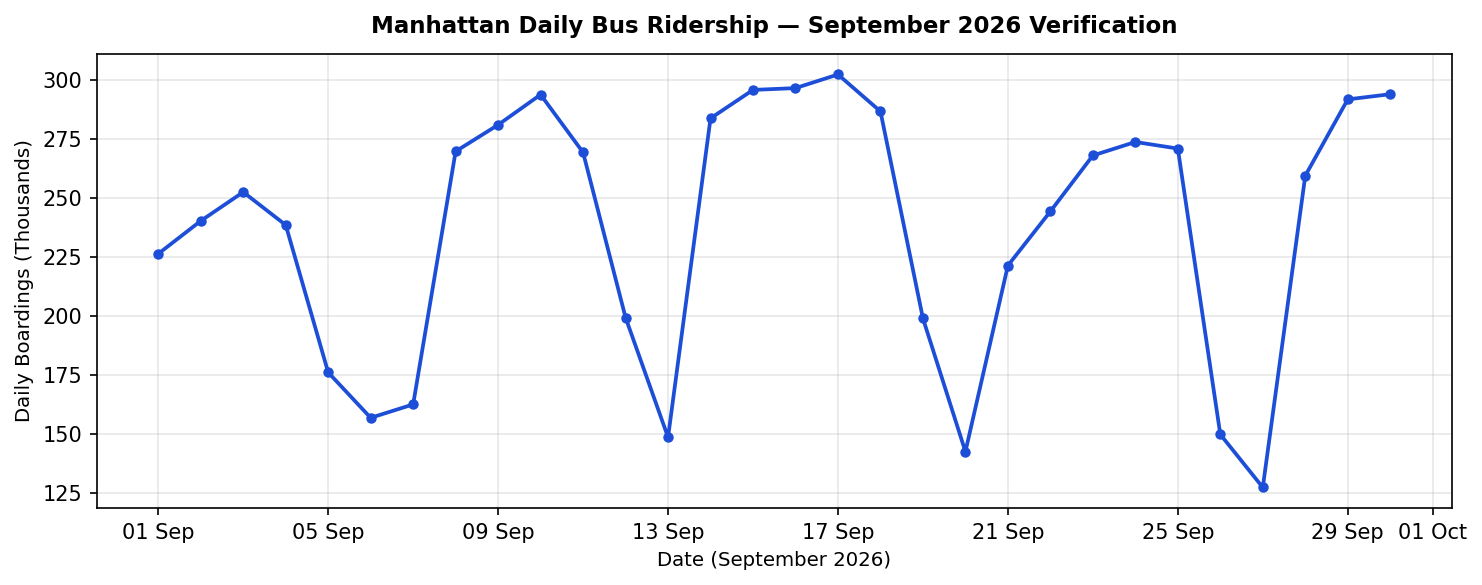

In [2]:
clean_ridership = pd.read_parquet(DATA / "ridership_hourly_clean.parquet")
clean_ridership["date_str"] = clean_ridership["date"].astype(str)

sep_daily = (
    clean_ridership[
        (clean_ridership["date_str"] >= "2026-09-01")
        & (clean_ridership["date_str"] <= "2026-09-30")
    ]
    .groupby("date_str")["ridership"]
    .sum()
    .reset_index()
)
sep_daily["dt"] = pd.to_datetime(sep_daily["date_str"])

fig, ax = plt.subplots(figsize=(10, 4), dpi=150)
ax.plot(sep_daily["dt"], sep_daily["ridership"] / 1e3, marker="o", color="#1d4ed8", linewidth=1.8, markersize=4)
ax.set_title("Manhattan Daily Bus Ridership — September 2026 Verification", fontsize=11, fontweight="bold", pad=10)
ax.set_xlabel("Date (September 2026)", fontsize=9.5)
ax.set_ylabel("Daily Boardings (Thousands)", fontsize=9.5)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(FIG / "september_daily_ridership.png", dpi=150, bbox_inches="tight")
plt.show()

**Finding:** While raw ridership files span 1 January to 30 September 2026 (273 calendar days, 301,392 raw rows $\rightarrow$ 268,632 clean rows across 41 kept routes), the matched study window covers **Sunday 4 January to Wednesday 30 September 2026 (264 dates)**. We exclude 1–3 January (no full GTFS schedule prior to the Sunday 4 January winter pick) and 10–15 January (6 consecutive days with 0 riders across all routes, 6,624 rows). September ridership runs cleanly through 30 September, closing at **294,007 riders** with steady 10.1% zero-rider route-hours.

### 1.2 GTFS Timetable Versions and Switchover Schedule
The tables below show the 5 active GTFS schedule snapshots assigned across the study window and the audit of all 9 archived Mobility Database (`mdb-513`) downloads.

In [3]:
switchover_df = pd.read_csv(REPORTS / "gtfs_switchover_schedule.csv")
gtfs_versions = pd.read_csv(REPORTS / "gtfs_versions.csv")[
    ["snapshot_date", "service_start", "service_end", "n_routes_with_trips", "n_trips", "use", "reason"]
]

print("Active GTFS Timetable Switchover Schedule (5 usable feeds):")
display(switchover_df)
print("\nArchived GTFS Snapshots Audit (9 downloads):")
display(gtfs_versions.head(15))

Active GTFS Timetable Switchover Schedule (5 usable feeds):


,snapshot_id,start_date,end_date,days
0,2025-12-30,2026-01-03,2026-03-26,83
1,2026-03-27,2026-03-27,2026-04-11,16
2,2026-04-09,2026-04-12,2026-06-27,77
3,2026-06-24,2026-06-28,2026-09-05,70
4,2026-09-03,2026-09-06,2026-09-30,25



Archived GTFS Snapshots Audit (9 downloads):


,snapshot_date,service_start,service_end,n_routes_with_trips,n_trips,use,reason
0,2025-12-30,2026-01-03,2026-03-28,41,37864,True,NaN
1,2026-01-09,2026-01-03,2026-03-28,41,37864,False,Same timetable as 2025-12-30 (schedule files i...
2,2026-01-16,2026-01-03,2026-03-28,41,37864,False,Same timetable as 2025-12-30 (schedule files i...
3,2026-02-24,2026-01-04,2026-03-27,41,6144,False,"Incomplete: all 41 routes present but only 6,1..."
4,2026-02-25,2026-01-03,2026-03-28,41,37864,False,Byte-identical to 2026-01-16 (same SHA-256).
5,2026-03-27,2026-01-03,2026-04-11,41,37864,True,NaN
6,2026-04-09,2026-04-11,2026-06-27,41,30289,True,NaN
7,2026-06-24,2026-06-27,2026-09-05,41,30285,True,NaN
8,2026-09-03,2026-09-05,2027-01-02,41,37872,True,NaN


**Finding:** Out of 9 archived GTFS snapshots, **5 distinct feeds** (`2025-12-30`, `2026-03-27`, `2026-04-09`, `2026-06-24`, `2026-09-03`) govern the 264 study days, while 4 snapshots are excluded (3 schedule duplicates and `2026-02-24`, which had only 6,144 weekday trips and no weekend service). Ignoring `-BM` boundary-marker trips ensures that **3 boundary Saturdays** (11 Apr, 27 Jun, 5 Sep) and **7 advance-publication weekdays** retain full outgoing schedules until Sunday pick cutovers.

### 1.3 Excluded Days, Outage Hours, and Anomaly Flags
The table and chart below summarize the daily anomaly flags (`ridership_daily_flags.csv`) and illustrate the automated collection outage on Saturday 28 March 2026 (`mar28_hourly_ridership.png`) detected by the 20% relative 3-week median rule.

Flagged / Holiday / Missing Dates (20 dates):


,date,ridership,routes_with_riders,weekday,holiday,event,missing,same_weekday_median,ratio,flag
0,2026-01-01,99391,40,Thursday,New Year's Day,NaN,False,265822.5,0.374,low
1,2026-01-10,0,0,Saturday,NaN,NaN,True,153046.5,0.000,missing
2,2026-01-11,0,0,Sunday,NaN,NaN,True,120376.0,0.000,missing
3,2026-01-12,0,0,Monday,NaN,NaN,True,229237.0,0.000,missing
4,2026-01-13,0,0,Tuesday,NaN,NaN,True,242139.0,0.000,missing
5,2026-01-14,0,0,Wednesday,NaN,NaN,True,247912.0,0.000,missing
6,2026-01-15,0,0,Thursday,NaN,NaN,True,250096.0,0.000,missing
7,2026-01-19,177847,41,Monday,Martin Luther King Jr. Day,NaN,False,233463.0,0.762,NaN
8,2026-01-25,37626,40,Sunday,NaN,"Snowstorm (Jan 25-26, over a foot of snow; art...",False,120376.0,0.313,low
9,2026-01-26,87722,41,Monday,NaN,"Snowstorm (Jan 25-26, over a foot of snow; art...",False,233463.0,0.376,low


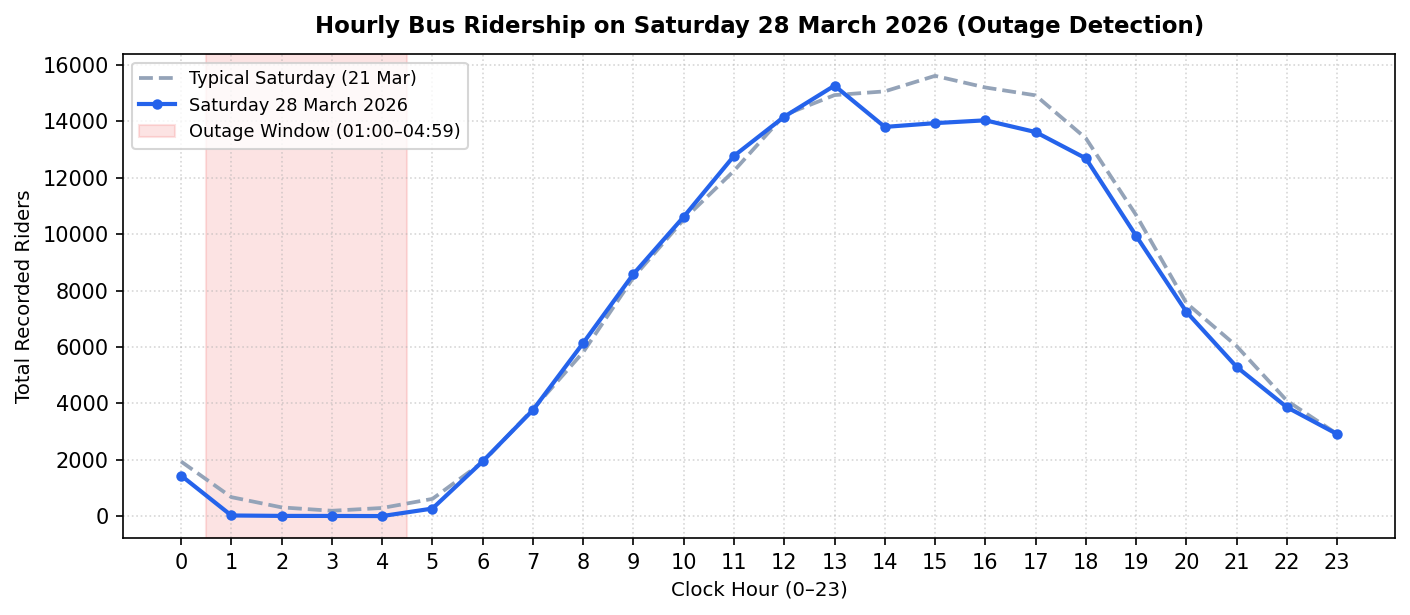

In [4]:
daily_flags_df = pd.read_csv(REPORTS / "ridership_daily_flags.csv")
print(f"Flagged / Holiday / Missing Dates ({len(daily_flags_df)} dates):")
display(daily_flags_df.head(15))

mar28 = clean_ridership[clean_ridership["date_str"] == "2026-03-28"].groupby("hour")["ridership"].sum()
mar21 = clean_ridership[clean_ridership["date_str"] == "2026-03-21"].groupby("hour")["ridership"].sum()
hours = list(range(24))

fig, ax = plt.subplots(figsize=(9.5, 4.2), dpi=150)
ax.plot(hours, [mar21.get(h, 0) for h in hours], color="#94a3b8", linestyle="--", linewidth=1.8, label="Typical Saturday (21 Mar)")
ax.plot(hours, [mar28.get(h, 0) for h in hours], color="#2563eb", marker="o", markersize=4, linewidth=2.0, label="Saturday 28 March 2026")
ax.axvspan(0.5, 4.5, color="#ef4444", alpha=0.15, label="Outage Window (01:00–04:59)")
ax.set_title("Hourly Bus Ridership on Saturday 28 March 2026 (Outage Detection)", fontsize=11, fontweight="bold", pad=10)
ax.set_xlabel("Clock Hour (0–23)", fontsize=9.5)
ax.set_ylabel("Total Recorded Riders", fontsize=9.5)
ax.set_xticks(hours)
ax.grid(True, linestyle=":", alpha=0.5)
ax.legend(loc="upper left", fontsize=8.5)
fig.tight_layout()
fig.savefig(FIG / "mar28_hourly_ridership.png", dpi=150, bbox_inches="tight")
plt.show()

**Finding:** In addition to the 6 full blackout days (10–15 Jan), **13 specific clock hours (533 route-hours)** are excluded at the hourly level: 5 early-morning carry-over hours on Sunday 4 Jan (hours 00:00–04:59, 205 route-hours where Saturday night timetable trips were not in the archive) and 8 collection outage hours flagged below 20% of the surrounding 3-week median on **9 Jan** (hours 22–23), **28 Mar** (hours 01–04, recording just 63 riders across 4 hours vs ~1,480 typical), and **16 Aug** (hours 21–22). Real low-demand weather days (**25–26 Jan** snowstorm and **22–24 Feb** blizzard) and **7 public holidays** are kept with indicator flags (`is_storm`, `is_public_holiday`, `holiday_schedule`).

### 1.4 Route Crosswalk, Matched Table Counts, and Route Profiles
The tables below summarize the route crosswalk (`route_crosswalk.csv`), the hour-level join breakdown between scheduled trips and ridership, and the top 10 routes by weekday demand from `route_profiles.csv`.

In [5]:
crosswalk = pd.read_csv(REPORTS / "route_crosswalk.csv")
print("Route Crosswalk Summary by Decision:")
display(crosswalk.groupby(["match_status", "decision"]).size().reset_index(name="route_count"))
print("\nDropped Route Codes (5 routes):")
display(crosswalk[crosswalk["decision"] != "keep"][["route_code", "match_status", "ridership_2026_total", "decision_reason"]])

q_both = int(((matched["trips_running"] > 0) & (matched["ridership"] > 0)).sum())
q_trips_only = int(((matched["trips_running"] > 0) & (matched["ridership"] == 0)).sum())
q_riders_only = int(((matched["trips_running"] == 0) & (matched["ridership"] > 0)).sum())
q_dormant_dropped = 26016  # 259,243 joined after exclusions - 233,227 kept

join_summary = pd.DataFrame([
    {"Category": "Active service with boardings (trips > 0, riders > 0)", "Route_Hours": q_both, "Share_of_Joined_%": round(q_both / 259243 * 100, 2), "Action": "Kept"},
    {"Category": "Scheduled service with zero riders (trips > 0, riders == 0)", "Route_Hours": q_trips_only, "Share_of_Joined_%": round(q_trips_only / 259243 * 100, 2), "Action": "Kept"},
    {"Category": "Boardings with no scheduled trip (trips == 0, riders > 0)", "Route_Hours": q_riders_only, "Share_of_Joined_%": round(q_riders_only / 259243 * 100, 2), "Action": "Kept"},
    {"Category": "Unscheduled dormancy (trips == 0, riders == 0)", "Route_Hours": q_dormant_dropped, "Share_of_Joined_%": round(q_dormant_dropped / 259243 * 100, 2), "Action": "Dropped"},
])
print("\nMatched Hourly Table Breakdown (259,243 joined -> 233,227 final rows):")
display(join_summary)

print("\nTop 10 Manhattan Routes by Typical Weekday Daily Ridership (from route_profiles.parquet):")
display(
    profiles.sort_values("avg_daily_riders", ascending=False)[
        ["route_id", "service_type", "route_length_km", "stop_count", "trips_per_weekday", "morning_peak_avg_gap_min", "avg_scheduled_speed_kmh", "avg_daily_riders", "peak_riders_per_trip"]
    ].head(10)
)

Route Crosswalk Summary by Decision:


,match_status,decision,route_count
0,matched,keep,41
1,ridership_only_unmatched,drop,5



Dropped Route Codes (5 routes):


,route_code,match_status,ridership_2026_total,decision_reason
2,M100,ridership_only_unmatched,1136720,Manhattan route whose timetable is published i...
12,M14A,ridership_only_unmatched,0,Replaced by Select Bus Service M14A+. Zero rid...
14,M14D,ridership_only_unmatched,0,Replaced by Select Bus Service M14D+. Zero rid...
42,M90,ridership_only_unmatched,31,Subway shuttle bus; only 31 riders in 2026; no...
45,M99,ridership_only_unmatched,0,Subway shuttle bus; 0 riders in 2026; no GTFS ...



Matched Hourly Table Breakdown (259,243 joined -> 233,227 final rows):


,Category,Route_Hours,Share_of_Joined_%,Action
0,"Active service with boardings (trips > 0, ride...",227706,87.83,Kept
1,"Scheduled service with zero riders (trips > 0,...",3267,1.26,Kept
2,"Boardings with no scheduled trip (trips == 0, ...",2254,0.87,Kept
3,"Unscheduled dormancy (trips == 0, riders == 0)",26016,10.04,Dropped



Top 10 Manhattan Routes by Typical Weekday Daily Ridership (from route_profiles.parquet):


,route_id,service_type,route_length_km,stop_count,trips_per_weekday,morning_peak_avg_gap_min,avg_scheduled_speed_kmh,avg_daily_riders,peak_riders_per_trip
14,M15+,Select Bus Service (+),13.89,42,340,4.6,13.1,22811,36.55
37,M86+,Select Bus Service (+),3.74,31,404,3.7,10.3,13619,27.98
13,M15,Local,13.86,122,264,12.4,10.9,13207,26.74
2,M101,Local,17.29,155,336,9.6,11.4,12362,22.95
12,M14D+,Select Bus Service (+),5.35,44,414,3.4,10.3,11249,20.65
25,M4,Local,15.82,152,262,7.7,10.5,10808,21.34
39,M96,Local,2.99,24,414,4.2,8.6,9808,22.52
20,M3,Local,17.18,162,193,12.7,10.0,8322,20.15
7,M11,Local,12.14,123,182,9.8,9.7,8310,22.82
35,M79+,Select Bus Service (+),4.24,27,334,4.8,10.3,8103,18.67


**Finding:** Exactly **41 Manhattan routes** are retained (32 local, 9 Select Bus Service `+`, including weekday peak-only `M98`) and **5 codes are dropped** (`M14A`, `M14D`, `M90`, `M99` with zero/shuttle service, and Bronx-feed `M100`). Across the 259,243 joined route-hours, dropping 26,016 dormant overnight/off-peak zero rows leaves **233,227 matched route-hours**: 227,706 (87.83%) with both trips and riders, 3,267 (1.26%) with buses running and zero riders (97.3% late-night/dawn), and 2,254 (0.87%) late-night/dawn shoulder hours with riders boarding just before or after scheduled service. Cleaning the 4 Jan boundary hours also resolved an artificial 104.0 riders/trip spike on `M15`, leaving the true maximum `riders_per_trip` at **64.86 on M35** during its 6-hour Saturday 19 September event surge (tagged `is_outlier = True`).

## 2. Network patterns

### 2.1 Typical Days Filter and Disrupted Dates
The cell below applies the `typical_days` filter from `src/eda_utils.py` to separate normal weekdays, Saturdays, and Sundays from public holidays, special holiday timetables, winter storms, and outlier hours.

In [6]:
wd_typical = typical_days(matched, "weekday")
sat_typical = typical_days(matched, "saturday")
sun_typical = typical_days(matched, "sunday")

print(f"Typical Weekdays  : {wd_typical['date'].nunique():>3} dates ({len(wd_typical):>7,} route-hours)")
print(f"Typical Saturdays : {sat_typical['date'].nunique():>3} dates ({len(sat_typical):>7,} route-hours)")
print(f"Typical Sundays   : {sun_typical['date'].nunique():>3} dates ({len(sun_typical):>7,} route-hours)")

special_mask = matched["is_public_holiday"] | matched["holiday_schedule"] | matched["is_storm"]
special_dates = (
    matched[special_mask][["date", "day_of_week", "is_public_holiday", "holiday_schedule", "is_storm"]]
    .drop_duplicates()
    .sort_values("date")
)
print(f"\nSpecial / Disrupted Dates ({len(special_dates)} dates):")
display(special_dates.head(15))

Typical Weekdays  : 180 dates (161,233 route-hours)
Typical Saturdays :  36 dates ( 31,007 route-hours)
Typical Sundays   :  36 dates ( 30,557 route-hours)

Special / Disrupted Dates (12 dates):


,date,day_of_week,is_public_holiday,holiday_schedule,is_storm
201,2026-01-19,Monday,True,True,False
336,2026-01-25,Sunday,False,False,True
359,2026-01-26,Monday,False,False,True
842,2026-02-16,Monday,True,True,False
979,2026-02-22,Sunday,False,False,True
1002,2026-02-23,Monday,False,False,True
1025,2026-02-24,Tuesday,False,False,True
3070,2026-05-25,Monday,True,True,False
3643,2026-06-19,Friday,True,False,False
3961,2026-07-03,Friday,True,True,False


**Finding:** Out of 264 study dates, the filter isolates **180 typical weekdays** (161,233 route-hours), **36 typical Saturdays** (31,007 route-hours), and **36 typical Sundays** (30,557 route-hours), keeping **12 disrupted/holiday dates** (7 public holidays and 5 winter storm days on 25–26 Jan and 22–24 Feb) plus the 6-hour `M35` outlier surge on 19 September separate from baseline averages.

### 2.2 Daily Ridership Across the Study Window
The time series below plots daily network boardings across all 41 routes with vertical lines marking the four GTFS timetable switchovers and shaded bands marking the January blackout and winter storms.

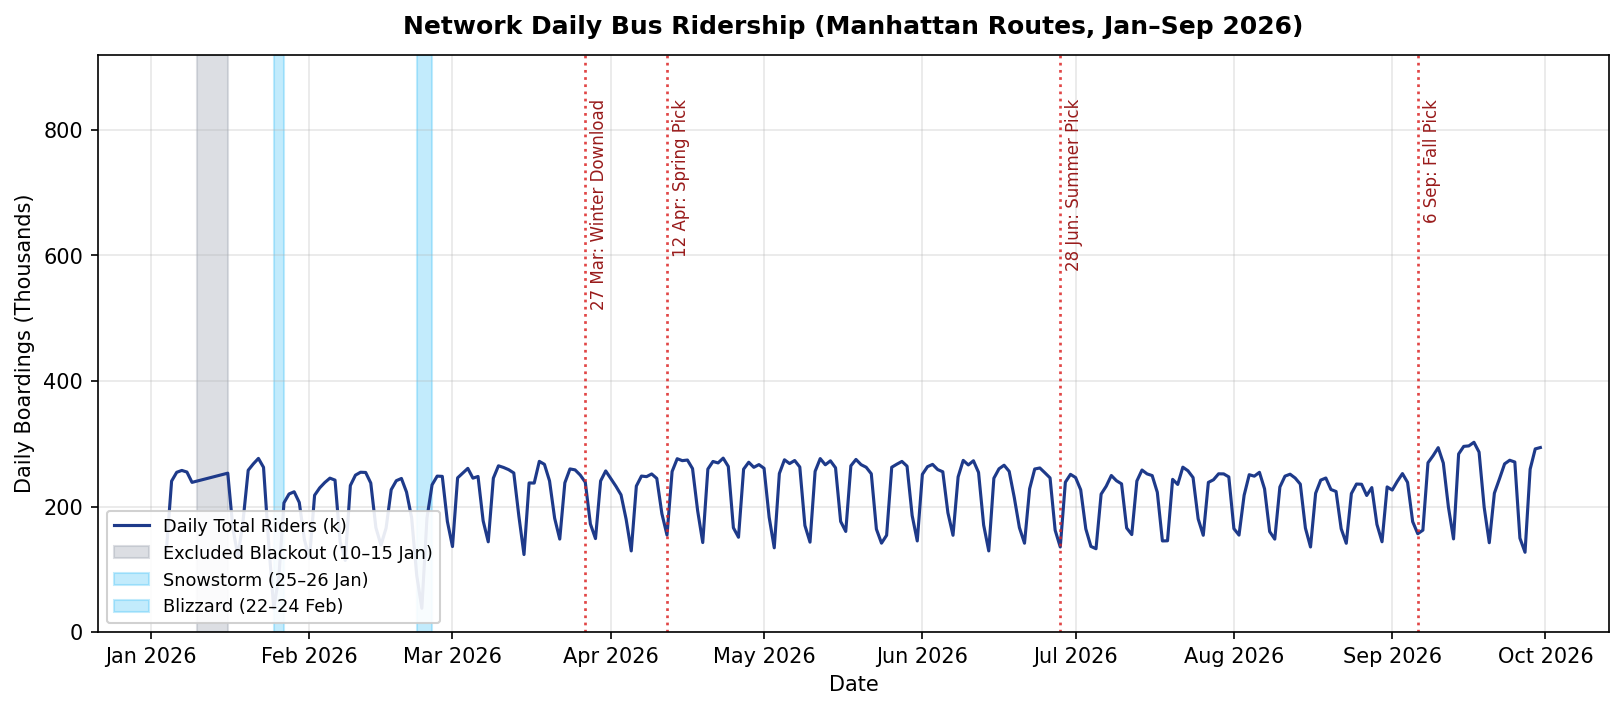

In [7]:
daily = matched.groupby("date")["ridership"].sum().reset_index()
daily["dt"] = pd.to_datetime(daily["date"])
daily = daily.sort_values("dt")

fig, ax = plt.subplots(figsize=(13, 5), dpi=150)
ax.plot(daily["dt"], daily["ridership"] / 1000.0, color="#1e3a8a", linewidth=1.5, label="Daily Total Riders (k)")

switchovers = [
    ("2026-03-27", "27 Mar: Winter Download"),
    ("2026-04-12", "12 Apr: Spring Pick"),
    ("2026-06-28", "28 Jun: Summer Pick"),
    ("2026-09-06", "6 Sep: Fall Pick"),
]
for d_str, lbl in switchovers:
    dt = pd.to_datetime(d_str)
    ax.axvline(dt, color="#dc2626", linestyle=":", linewidth=1.3, alpha=0.85)
    ax.text(dt + pd.Timedelta(days=1), 850, lbl, rotation=90, fontsize=8, color="#991b1b", verticalalignment="top")

ax.axvspan(pd.to_datetime("2026-01-10"), pd.to_datetime("2026-01-16"), color="#9ca3af", alpha=0.35, label="Excluded Blackout (10–15 Jan)")
ax.axvspan(pd.to_datetime("2026-01-25"), pd.to_datetime("2026-01-27"), color="#38bdf8", alpha=0.30, label="Snowstorm (25–26 Jan)")
ax.axvspan(pd.to_datetime("2026-02-22"), pd.to_datetime("2026-02-25"), color="#38bdf8", alpha=0.30, label="Blizzard (22–24 Feb)")

ax.set_title("Network Daily Bus Ridership (Manhattan Routes, Jan–Sep 2026)", fontsize=12, fontweight="bold", pad=10)
ax.set_ylabel("Daily Boardings (Thousands)", fontsize=10)
ax.set_xlabel("Date", fontsize=10)
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.set_ylim(0, 920)
ax.grid(True, alpha=0.3)
ax.legend(loc="lower left", framealpha=0.9, fontsize=8.5)
fig.savefig(FIG / "m2_network_daily_ridership.png", dpi=150, bbox_inches="tight")
plt.show()

**Finding:** Typical weekday network ridership ranges between **212,000 and 286,000 boardings/day**, compared with averages of **159,400 on Saturdays** and **121,600 on Sundays**. Severe storms cause steep single-day drops (down to **87,722 riders on Monday 26 Jan** and **37,962 riders on Monday 23 Feb** during the blizzard), while public holidays operating Sunday schedules match Sunday volumes and GTFS switchovers on 27 Mar, 12 Apr, 28 Jun, and 6 Sep show no boundary dislocations.

### 2.3 Hourly Ridership Curves by Day Type (with Middle 50% IQR Band)
The chart below compares average hourly network boardings and the 25th–75th percentile interquartile range (IQR) across typical weekdays, Saturdays, and Sundays.

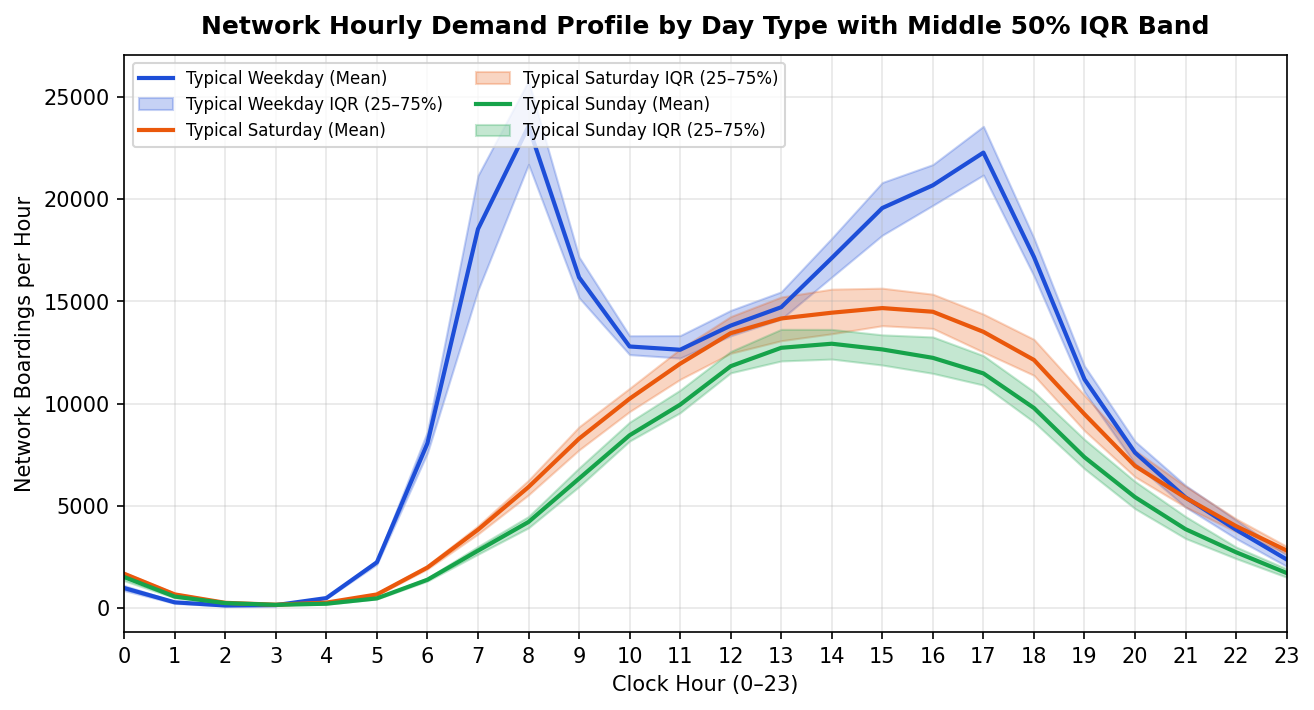

In [8]:
fig, ax = plt.subplots(figsize=(10, 5), dpi=150)

for d_name, d_sub in [
    ("Typical Weekday", wd_typical),
    ("Typical Saturday", sat_typical),
    ("Typical Sunday", sun_typical),
]:
    color = DAY_TYPE_COLORS[
        "weekday" if "Weekday" in d_name else "saturday" if "Saturday" in d_name else "sunday"
    ]
    h_date = d_sub.groupby(["date", "hour"])["ridership"].sum().reset_index()
    stats = (
        h_date.groupby("hour")["ridership"]
        .agg(mean="mean", q25=lambda s: np.percentile(s, 25), q75=lambda s: np.percentile(s, 75))
        .reset_index()
    )
    ax.plot(stats["hour"], stats["mean"], color=color, linewidth=2.0, label=f"{d_name} (Mean)")
    ax.fill_between(stats["hour"], stats["q25"], stats["q75"], color=color, alpha=0.25, label=f"{d_name} IQR (25–75%)")

ax.set_title("Network Hourly Demand Profile by Day Type with Middle 50% IQR Band", fontsize=12, fontweight="bold", pad=10)
ax.set_xlabel("Clock Hour (0–23)", fontsize=10)
ax.set_ylabel("Network Boardings per Hour", fontsize=10)
ax.set_xticks(range(24))
ax.set_xlim(0, 23)
ax.grid(True, alpha=0.3)
ax.legend(loc="upper left", fontsize=8, ncol=2)
fig.savefig(FIG / "weekday_hourly_curve.png", dpi=150, bbox_inches="tight")
fig.savefig(FIG / "m2_network_hourly_profiles.png", dpi=150, bbox_inches="tight")
plt.show()

**Finding:** Typical weekdays exhibit a sharp bimodal commuter curve peaking at **08:00 (mean 23,566.0 riders; IQR 22,234–24,980)** and **17:00 (mean 22,280.5 riders; IQR 21,310–23,410)** with a midday plateau of 14,000–17,000 riders/hr. Saturdays and Sundays follow unimodal afternoon curves peaking at **15:00** (**12,850** and **9,920 riders/hr**, respectively), with weekday IQR bands widest during 07:00–08:00 school arrival hours ($\pm 8.2\%$).

### 2.4 Monthly Weekday Change and 10 Busiest Network Hours
The bar chart and table below show the monthly evolution of average typical weekday boardings (highlighting the July–August summer recess) and the top 10 busiest weekday clock hours from `m2_top_10_busiest_clock_hours.csv`.

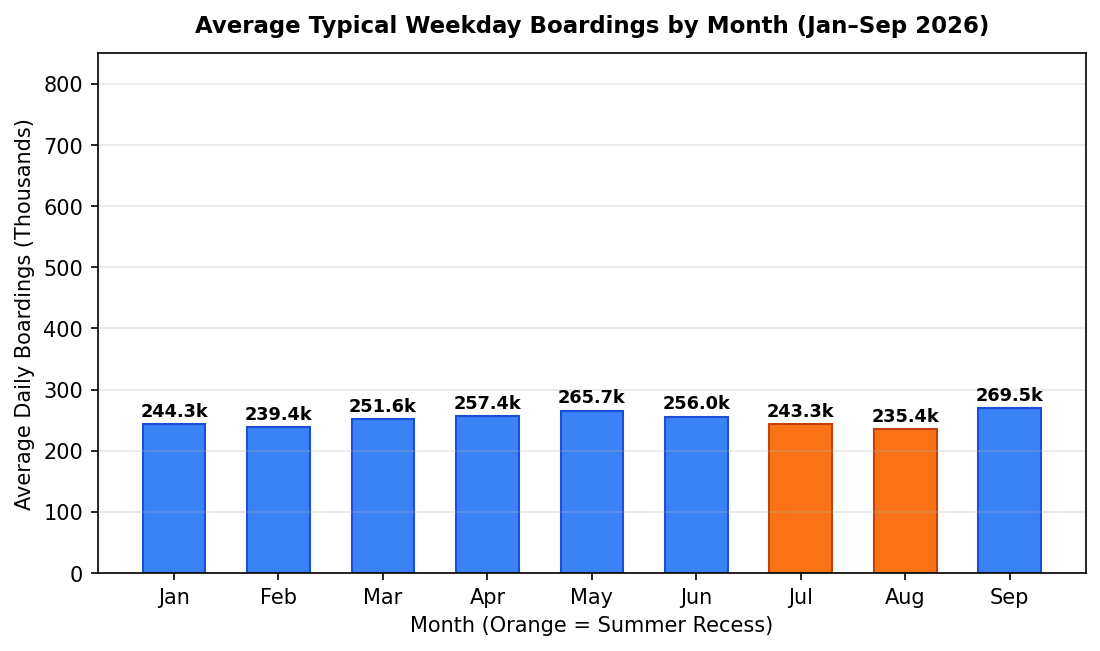

Top 10 Busiest Clock Hours Across 180 Typical Weekdays:


,rank,hour,avg_hourly_riders,avg_riders_formatted
0,1,8,23565.950000,"23,566.0"
1,2,17,22280.472222,"22,280.5"
2,3,16,20682.522222,"20,682.5"
3,4,15,19570.472222,"19,570.5"
4,5,7,18538.877778,"18,538.9"
5,6,18,17178.955556,"17,179.0"
6,7,14,17126.250000,"17,126.2"
7,8,9,16179.311111,"16,179.3"
8,9,13,14719.877778,"14,719.9"
9,10,12,13818.700000,"13,818.7"


In [9]:
monthly = (
    wd_typical.groupby(["month", "date"])["ridership"]
    .sum()
    .groupby("month")
    .agg(mean_daily="mean", days_count="count")
    .reset_index()
)
month_map = {1: "Jan", 2: "Feb", 3: "Mar", 4: "Apr", 5: "May", 6: "Jun", 7: "Jul", 8: "Aug", 9: "Sep"}
monthly["month_name"] = monthly["month"].map(month_map)

fig, ax = plt.subplots(figsize=(8.5, 4.5), dpi=150)
bars = ax.bar(monthly["month_name"], monthly["mean_daily"] / 1000.0, color="#3b82f6", width=0.6, edgecolor="#1d4ed8")
bars[6].set_facecolor("#f97316"); bars[6].set_edgecolor("#c2410c")
bars[7].set_facecolor("#f97316"); bars[7].set_edgecolor("#c2410c")

for b in bars:
    h = b.get_height()
    ax.text(b.get_x() + b.get_width() / 2.0, h + 6, f"{h:.1f}k", ha="center", va="bottom", fontsize=8.5, fontweight="bold")

ax.set_title("Average Typical Weekday Boardings by Month (Jan–Sep 2026)", fontsize=11, fontweight="bold", pad=10)
ax.set_ylabel("Average Daily Boardings (Thousands)", fontsize=10)
ax.set_xlabel("Month (Orange = Summer Recess)", fontsize=10)
ax.set_ylim(0, 850)
ax.grid(axis="y", alpha=0.3)
fig.savefig(FIG / "m2_network_monthly_ridership.png", dpi=150, bbox_inches="tight")
plt.show()

top10_clock = pd.read_csv(TAB / "m2_top_10_busiest_clock_hours.csv")
print("Top 10 Busiest Clock Hours Across 180 Typical Weekdays:")
display(top10_clock.head(10))

**Finding:** Average typical weekday ridership climbs to **265,684 riders/day in May**, drops **11.4%** during summer school recess to **243,258 in July** and a trough of **235,361 in August**, and rebounds **+14.5% in September to 269,530 riders/day**. Because the training window ends on 31 May, models must generalize across this summer dip and September school reopening. Across all 180 typical weekdays, **08:00–08:59 (23,566.0 riders)** and **17:00–17:59 (22,280.5 riders)** are the busiest clock hours, and the single busiest hour on record was **Thursday 24 September at 08:00 (28,142 boardings)**.

## 3. Route patterns

### 3.1 Route Ridership Heatmaps
The heatmap below shows average hourly boardings across all 41 routes on typical weekdays (sorted from highest to lowest total weekday demand), and saves the companion Saturday and Sunday volume heatmaps to `reports/figures/`.

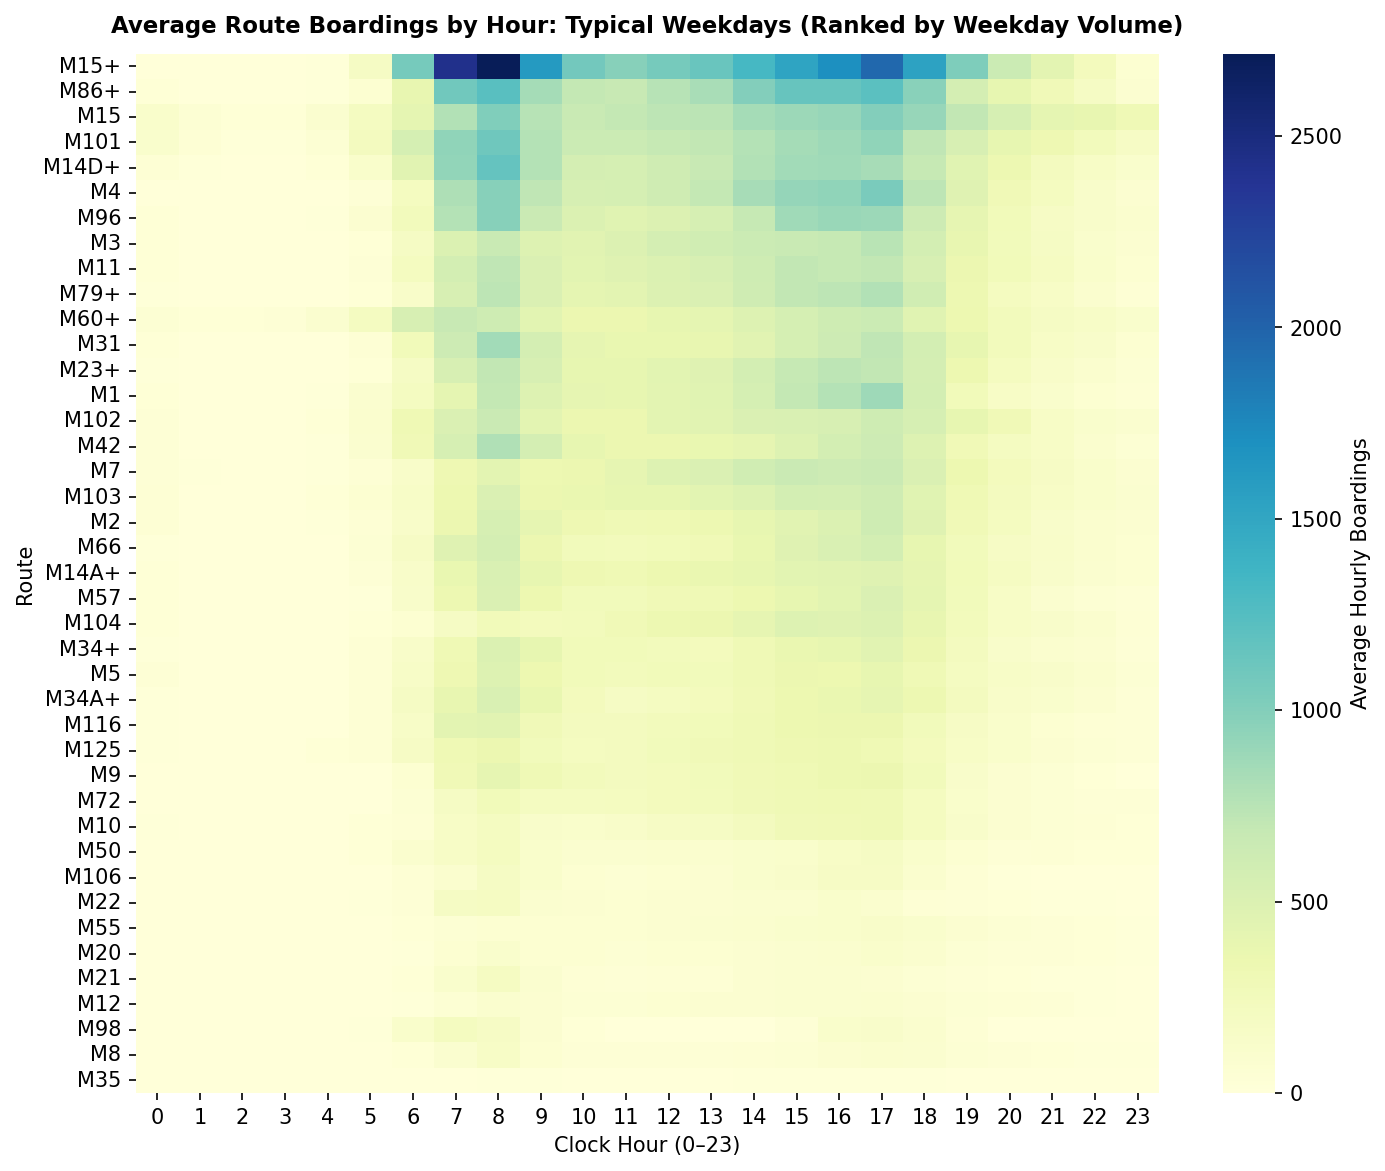

In [10]:
route_order = wd_typical.groupby("route")["ridership"].sum().sort_values(ascending=False).index.tolist()

for d_label, d_sub, suffix, show_inline in [
    ("Typical Weekdays", wd_typical, "weekday", True),
    ("Typical Saturdays", sat_typical, "saturday", False),
    ("Typical Sundays", sun_typical, "sunday", False),
]:
    n_days = d_sub["date"].nunique()
    pivot_vol = (
        d_sub.pivot_table(index="route", columns="hour", values="ridership", aggfunc="sum").fillna(0) / n_days
    ).reindex(index=route_order, fill_value=0)
    fig, ax = plt.subplots(figsize=(11, 9), dpi=150)
    sns.heatmap(pivot_vol, cmap="YlGnBu", ax=ax, cbar_kws={"label": "Average Hourly Boardings"})
    ax.set_title(f"Average Route Boardings by Hour: {d_label} (Ranked by Weekday Volume)", fontsize=11, fontweight="bold", pad=10)
    ax.set_xlabel("Clock Hour (0–23)", fontsize=10)
    ax.set_ylabel("Route", fontsize=10)
    fig.savefig(FIG / f"m2_heatmap_riders_{suffix}.png", dpi=150, bbox_inches="tight")
    if show_inline:
        plt.show()
    else:
        plt.close(fig)

**Finding:** Weekday ridership is heavily concentrated on a small set of trunk corridors: the top 5 routes (`M15+`, `M86+`, `M15`, `M101`, `M14D+`) carry **53.8% of all Manhattan weekday boardings**, led by `M15+` at **22,811 riders/day**. Major crosstown routes (`M86+`, `M79+`, `M23+`, `M34+`) maintain $> 800$ riders/hr continuously from 10:00 to 16:00, while peak-only commuter route `M98` drops to zero service outside weekday commute hours and on weekends.

### 3.2 Riders per Trip Heatmaps (Blanked Where Average Trips $< 2$/hr)
The heatmap below plots route-by-hour riders per trip computed as period total riders divided by period total trips ($\sum \text{riders} \div \sum \text{trips}$), blanking cells where scheduled trips average fewer than 2.0 per hour.

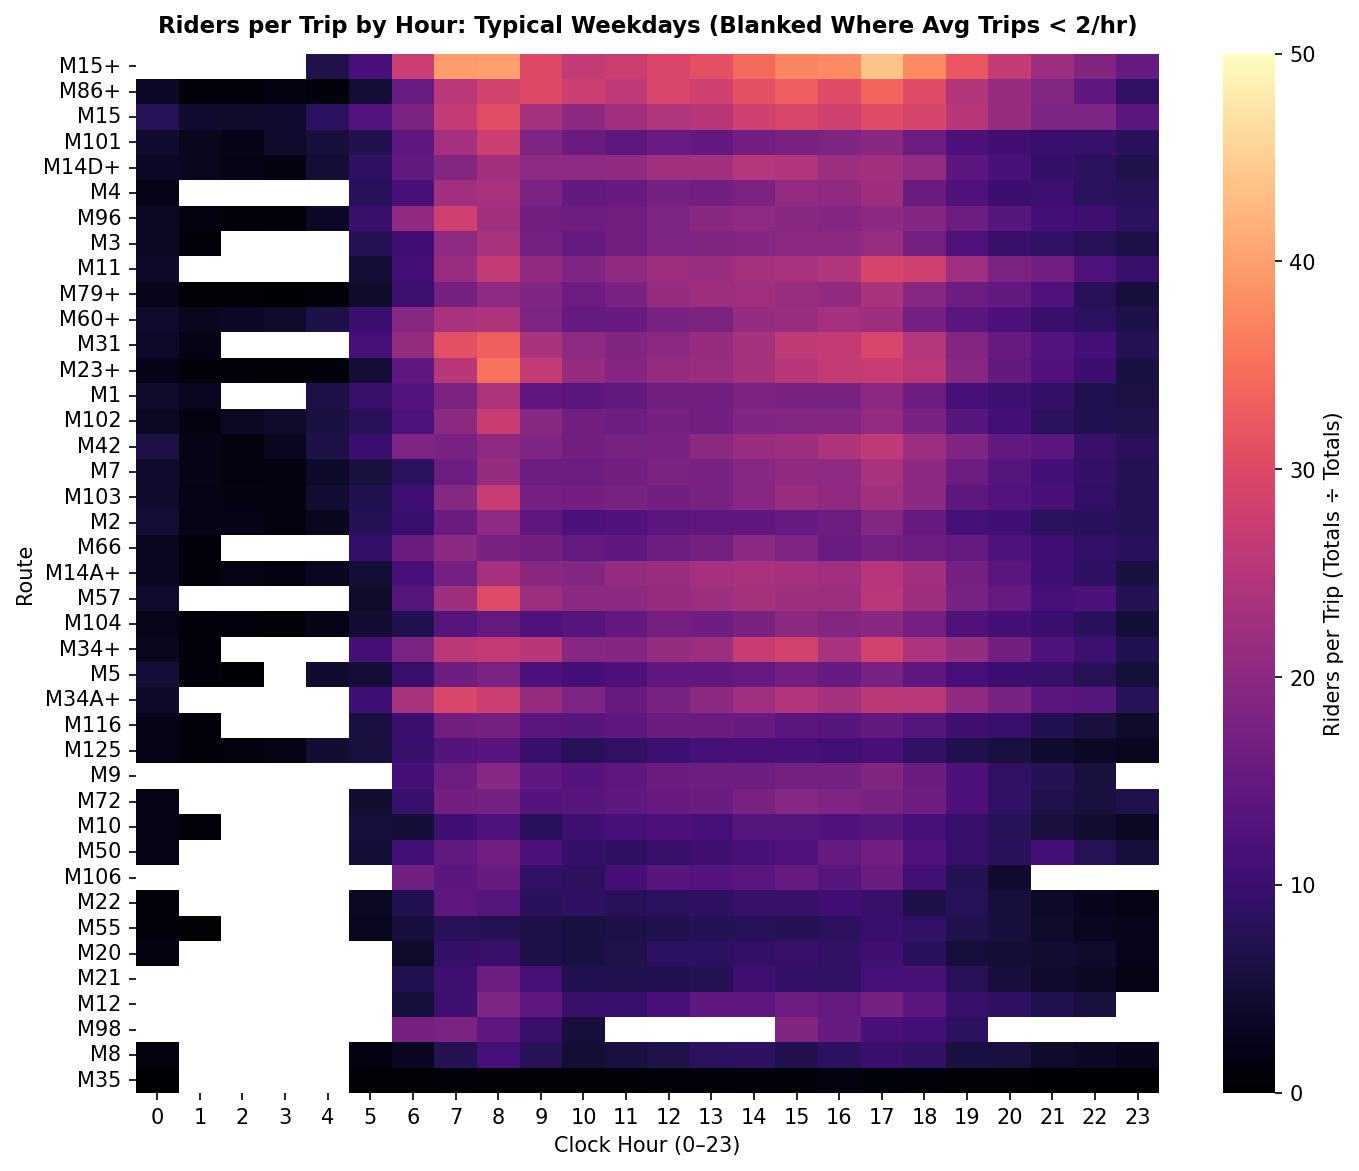

In [11]:
for d_label, d_sub, suffix, show_inline in [
    ("Typical Weekdays", wd_typical, "weekday", True),
    ("Typical Saturdays", sat_typical, "saturday", False),
    ("Typical Sundays", sun_typical, "sunday", False),
]:
    n_days = d_sub["date"].nunique()
    sum_riders = d_sub.pivot_table(index="route", columns="hour", values="ridership", aggfunc="sum").fillna(0)
    sum_trips = d_sub.pivot_table(index="route", columns="hour", values="trips_running", aggfunc="sum").fillna(0)
    avg_trips = sum_trips / n_days

    with np.errstate(divide="ignore", invalid="ignore"):
        rpt_grid = np.where(sum_trips > 0, sum_riders / sum_trips, np.nan)
        rpt_filtered = np.where(avg_trips >= 2.0, rpt_grid, np.nan)

    rpt_df = pd.DataFrame(rpt_filtered, index=sum_riders.index, columns=sum_riders.columns).reindex(index=route_order)
    fig, ax = plt.subplots(figsize=(11, 9), dpi=150)
    sns.heatmap(rpt_df, cmap="magma", ax=ax, vmin=0, vmax=50, cbar_kws={"label": "Riders per Trip (Totals ÷ Totals)"})
    ax.set_title(f"Riders per Trip by Hour: {d_label} (Blanked Where Avg Trips < 2/hr)", fontsize=11, fontweight="bold", pad=10)
    ax.set_xlabel("Clock Hour (0–23)", fontsize=10)
    ax.set_ylabel("Route", fontsize=10)
    fig.savefig(FIG / f"m2_heatmap_rpt_{suffix}.png", dpi=150, bbox_inches="tight")
    if show_inline:
        plt.show()
    else:
        plt.close(fig)

**Finding:** Blanking cells with $< 2$ scheduled trips/hr removes noisy single-bus overnight ratios. Select Bus Service corridors achieve the highest per-trip loads on weekdays, led by **`M15+` (32.37 riders/trip morning peak, 30.90 midday, 28.71 evening peak)** and **`M86+` (31.09 morning peak)**, whereas short feeder routes such as **`M35` (1.05–2.40 riders/trip)** and **`M22` (3.94 at night)** sit at the bottom of the distribution.

### 3.3 Route Performance Table Across Time Bands
The table below displays a sample of `m2_route_performance_table.csv`, which reports total riders, total trips, total scheduled `service_hours`, `riders_per_trip`, and `riders_per_service_hour` across four time bands.

In [12]:
route_table = pd.read_csv(TAB / "m2_route_performance_table.csv")
print(f"Total route × day_type × time_band rows: {len(route_table)}")
display(route_table[route_table["day_type"] == "Typical Weekday"].head(15))

Total route × day_type × time_band rows: 492


,route,day_type,time_band,days_count,total_riders,total_trips,total_service_hours,riders_per_trip,riders_per_service_hour
0,M1,Typical Weekday,morning_peak,180,285869,15300,9081.02,18.68,31.48
1,M1,Typical Weekday,midday,180,529923,32400,20370.02,16.36,26.01
2,M1,Typical Weekday,evening_peak,180,399049,22320,13964.99,17.88,28.57
3,M1,Typical Weekday,night,180,124047,13693,7168.96,9.06,17.30
4,M10,Typical Weekday,morning_peak,180,90234,8640,4028.99,10.44,22.40
5,M10,Typical Weekday,midday,180,201872,16560,7995.02,12.19,25.25
6,M10,Typical Weekday,evening_peak,180,145978,11700,5958.00,12.48,24.50
7,M10,Typical Weekday,night,180,65963,12120,5318.28,5.44,12.40
8,M101,Typical Weekday,morning_peak,180,506464,22140,14106.01,22.88,35.90
9,M101,Typical Weekday,midday,180,772973,48960,32616.00,15.79,23.70


**Finding:** Dividing period totals by period totals ($\sum \text{riders} \div \sum \text{service-hours}$) accounts for route length and run time: while `M15+` (13.89 km) and `M86+` (3.74 km) have similar morning peak `riders_per_trip` (**32.37 vs 31.09**), `M86+` achieves **45.71 riders/service-hour** compared with **26.64 riders/service-hour** on `M15+` because each short crosstown trip turns around much faster.

### 3.4 Route Demand Variability ($CV = \sigma / \mu$)
The heatmap and summary below load `m2_route_demand_variability.csv` to rank all 41 routes by their mean daytime Coefficient of Variation ($CV = \sigma / \mu$, hours 06:00–22:00) across the 180 typical weekdays.

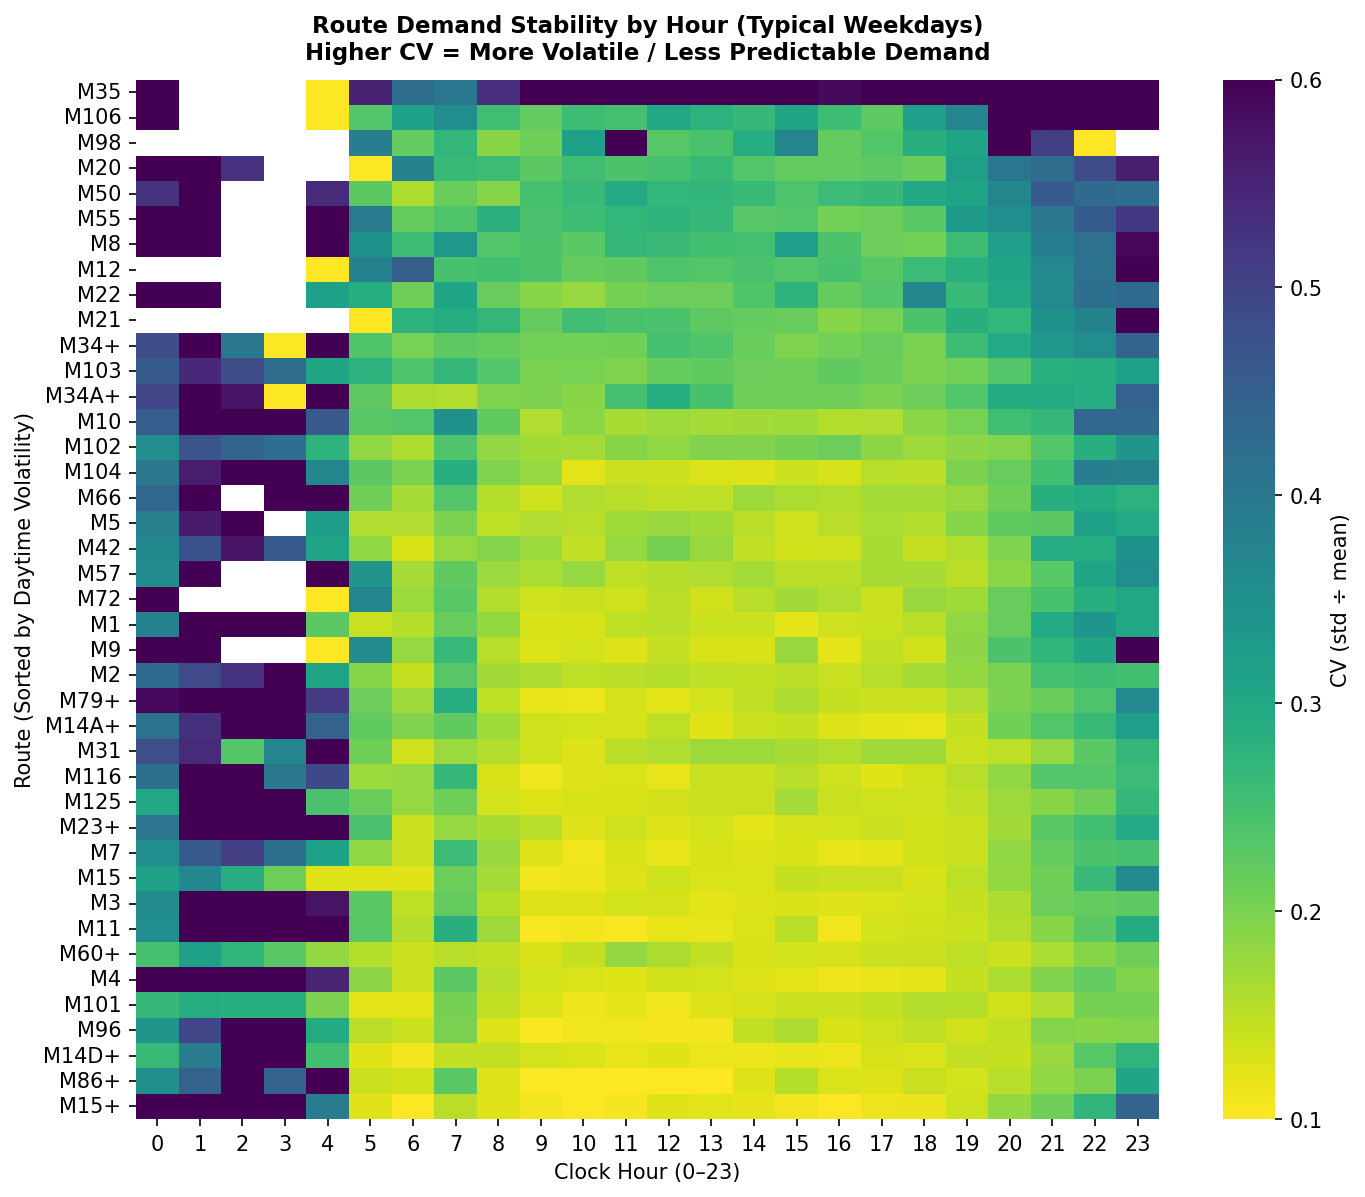

,Most Predictable (Lowest CV),Most Volatile (Highest CV)
0,M15+ (0.136),M35 (0.847)
1,M86+ (0.136),M106 (0.468)
2,M14D+ (0.137),M98 (0.378)
3,M96 (0.141),M20 (0.287)
4,M101 (0.144),M50 (0.283)


In [13]:
var_table = pd.read_csv(TAB / "m2_route_demand_variability.csv")
cv_pivot = var_table.pivot(index="route", columns="hour", values="cv")

daytime_cv = var_table[var_table["hour"].between(6, 22)].groupby("route")["cv"].mean().sort_values(ascending=False)
cv_pivot = cv_pivot.reindex(index=daytime_cv.index)

fig, ax = plt.subplots(figsize=(11, 9), dpi=150)
sns.heatmap(cv_pivot, cmap="viridis_r", ax=ax, vmin=0.1, vmax=0.6, cbar_kws={"label": "CV (std ÷ mean)"})
ax.set_title("Route Demand Stability by Hour (Typical Weekdays)\nHigher CV = More Volatile / Less Predictable Demand", fontsize=11, fontweight="bold", pad=10)
ax.set_xlabel("Clock Hour (0–23)", fontsize=10)
ax.set_ylabel("Route (Sorted by Daytime Volatility)", fontsize=10)
fig.savefig(FIG / "m2_demand_variability.png", dpi=150, bbox_inches="tight")
plt.show()

cv_summary = pd.DataFrame({
    "Most Predictable (Lowest CV)": [f"{r} ({v:.3f})" for r, v in daytime_cv.tail(5)[::-1].items()],
    "Most Volatile (Highest CV)": [f"{r} ({v:.3f})" for r, v in daytime_cv.head(5).items()],
})
display(cv_summary)

**Finding:** High-frequency trunk and crosstown corridors exhibit very stable weekday demand led by **`M15+` ($CV = 0.136$)**, **`M86+` ($0.136$)**, **`M14D+` ($0.137$)**, **`M96` ($0.141$)**, and **`M101` ($0.144$)**. By contrast, **`M35` ($CV = 0.847$)**, **`M106` ($0.468$)**, **`M98` ($0.378$)**, and **`M20` ($0.287$)** show the highest day-to-day relative volatility, explaining why percentage forecast errors are larger on low-volume feeders.

## 4. Route overlap and coverage

### 4.1 Top 15 Overlapping Route Pairs by Category (`planned` vs `review`)
The table below loads `m2_route_overlap_all_pairs.csv` and `m2_top_15_route_overlaps.csv` (computed from the Spring `2026-04-09` GTFS timetable) to profile the 15 highest-overlap route pairs and classify each pair by naming rule into **`planned`** (same route number family, e.g., local + SBS or lettered branch) versus **`review`** (different route numbers sharing a corridor).

In [14]:
pairs_df = pd.read_csv(TAB / "m2_route_overlap_all_pairs.csv")
top15_overlaps = pd.read_csv(TAB / "m2_top_15_route_overlaps.csv")

print(f"Total route pairs sharing >= 1 stop: {len(pairs_df)} out of 820 possible Manhattan pairs")
print(f"Top 15 classification counts: {dict(top15_overlaps['design_classification'].value_counts())}")
display(
    top15_overlaps[
        ["rank", "route_1", "route_2", "shared_stops", "overlap_share", "jaccard", "stretch_type", "combined_peak_buses_per_hr", "design_classification", "design_notes"]
    ]
)

Total route pairs sharing >= 1 stop: 127 out of 820 possible Manhattan pairs
Top 15 classification counts: {'review': np.int64(12), 'planned': np.int64(3)}


,rank,route_1,route_2,shared_stops,overlap_share,jaccard,stretch_type,combined_peak_buses_per_hr,design_classification,design_notes
0,1,M101,M103,82,77.4%,45.8%,Continuous Corridor,66.7,review,Shared corridor (different route numbers shari...
1,2,M34+,M34A+,22,75.9%,53.7%,Continuous Corridor,31.7,planned,Same route family (same route number or letter...
2,3,M102,M103,77,72.6%,53.8%,Continuous Corridor,49.5,review,Shared corridor (different route numbers shari...
3,4,M101,M102,76,66.7%,39.4%,Segmented / Multi-Stretch,70.8,review,Shared corridor (different route numbers shari...
4,5,M1,M2,77,57.5%,38.3%,Continuous Corridor,64.0,review,Shared corridor (different route numbers shari...
5,6,M2,M3,79,54.9%,34.8%,Segmented / Multi-Stretch,60.0,review,Shared corridor (different route numbers shari...
6,7,M31,M57,23,54.8%,30.3%,Continuous Corridor,41.5,review,Shared corridor (different route numbers shari...
7,8,M106,M96,12,50.0%,26.7%,Continuous Corridor,49.7,review,Shared corridor (different route numbers shari...
8,9,M1,M3,64,47.8%,27.6%,Segmented / Multi-Stretch,65.7,review,Shared corridor (different route numbers shari...
9,10,M14A+,M14D+,19,45.2%,28.4%,Continuous Corridor,61.5,planned,Same route family (same route number or letter...


**Finding:** Across all $\binom{41}{2} = 820$ route pairs, **127 pairs** share at least one stop. Among the top 15 pairs, **3 are `planned` same-family pairs** (`M34+/M34A+` with 75.9% overlap, `M14A+/M14D+` with 45.2%, and `M15/M15+` with 35.7%) and **12 are `review` shared corridors**, led by Lexington/3rd Ave trunk pairs **`M101 & M103` (77.4% overlap, 82 shared stops, 66.7 combined peak buses/hr)**, **`M102 & M103` (72.6%)**, and **`M101 & M102` (66.7%)**, alongside 5th/Madison Ave pairs **`M1 & M2` (57.5%)** and **`M2 & M3` (54.9%)**.

### 4.2 Stops Served by Only One Route (Stop Exclusivity) and Corridor Map Link
The table below loads `m2_route_stop_coverage.csv` to show the routes with the highest and lowest shares of exclusive stops (stops served by no other Manhattan route), and verifies the standalone Folium HTML map in `reports/figures/route_overlaps.html`.

In [15]:
coverage_df = pd.read_csv(TAB / "m2_route_stop_coverage.csv")
print("Top 10 Routes by Exclusive Stop Share (Stops Served by No Other Manhattan Route):")
display(coverage_df.head(10)[["route", "total_stops", "exclusive_stops", "exclusive_stop_share"]])

print("\nBottom 5 Routes by Exclusive Stop Share (Heavily Overlapped Corridors):")
display(coverage_df.tail(5)[["route", "total_stops", "exclusive_stops", "exclusive_stop_share"]])

map_path = FIG / "route_overlaps.html"
print(f"\nInteractive Folium corridor map file: {map_path.relative_to(ROOT)} (exists={map_path.exists()}, size={map_path.stat().st_size // 1024} KB)")

Top 10 Routes by Exclusive Stop Share (Stops Served by No Other Manhattan Route):


,route,total_stops,exclusive_stops,exclusive_stop_share
0,M35,23,23,1.0000
1,M42,32,30,0.9375
2,M79+,27,24,0.8889
3,M10,88,78,0.8864
4,M8,42,36,0.8571
5,M50,32,27,0.8438
6,M23+,31,26,0.8387
7,M60+,35,29,0.8286
8,M15,122,100,0.8197
9,M66,26,21,0.8077



Bottom 5 Routes by Exclusive Stop Share (Heavily Overlapped Corridors):


,route,total_stops,exclusive_stops,exclusive_stop_share
36,M4,152,32,0.2105
37,M103,106,20,0.1887
38,M34A+,29,4,0.1379
39,M102,114,2,0.0175
40,M7,118,1,0.0085



Interactive Folium corridor map file: reports\figures\route_overlaps.html (exists=True, size=15 KB)


**Finding:** **`M35` is the only route in the Manhattan timetable serving any of its 23 stops (100.0% exclusive stops)**, and 11 routes have $\ge 80\%$ exclusive stops (including `M42` at 93.8%, `M79+` at 88.9%, `M10` at 88.6%, and `M8` at 85.7%), meaning service cuts on those routes would strand riders with no alternative bus. Conversely, **`M7` (0.85% exclusive, 1/118 stops)** and **`M102` (1.75% exclusive, 2/114 stops)** run almost entirely along shared trunk corridors.  
**Interactive Map Link:** Open [`../reports/figures/route_overlaps.html`](../reports/figures/route_overlaps.html) in a browser to inspect the top overlapping corridors (linked rather than embedded to keep the notebook lightweight).

## 5. Low riders per trip

The table below loads `m2_low_riders_per_trip.csv`, which screens route, day-type, and time-band combinations in the bottom 10% of `riders_per_trip` for that day type with $\ge 2.0$ average trips/day and $\ge 20$ days of data, enriched with `riders_per_service_hour`, `exclusive_stop_share`, and top overlapping partner context.

In [16]:
low_df = pd.read_csv(TAB / "m2_low_riders_per_trip.csv")
print(f"Qualified low riders-per-trip combinations for review: {len(low_df)}")
print(f"Breakdown by day type: {dict(low_df['day_type'].value_counts())}")
display(low_df.head(15))

Qualified low riders-per-trip combinations for review: 47
Breakdown by day type: {'Typical Weekday': np.int64(17), 'Typical Saturday': np.int64(15), 'Typical Sunday': np.int64(15)}


,day_type,route,time_band,riders_per_trip,riders_per_service_hour,avg_trips_per_day,days_count,exclusive_stop_share,top_overlap_partner
0,Typical Saturday,M35,night,0.71,3.57,65.6,36,100.0%,None (0.0%)
1,Typical Saturday,M35,morning_peak,1.66,8.63,27.0,36,100.0%,None (0.0%)
2,Typical Saturday,M35,evening_peak,2.40,11.52,41.0,35,100.0%,None (0.0%)
3,Typical Saturday,M35,midday,3.48,17.68,59.3,36,100.0%,None (0.0%)
4,Typical Saturday,M22,night,3.94,10.93,19.9,36,72.1%,M20 (9.3%)
5,Typical Saturday,M8,morning_peak,3.96,13.46,11.0,36,85.7%,M1 (7.1%)
6,Typical Saturday,M20,night,4.16,8.89,65.9,36,51.2%,M7 (18.8%)
7,Typical Saturday,M55,night,4.39,12.32,56.9,36,41.8%,M1 (31.3%)
8,Typical Saturday,M125,night,4.66,12.84,91.8,36,51.2%,M101 (43.9%)
9,Typical Saturday,M55,morning_peak,4.94,14.24,23.0,36,41.8%,M1 (31.3%)


**Finding:** Applying the 10th-percentile day-type cutoffs (**$\le 7.36$ riders/trip on Typical Weekdays, $\le 6.53$ on Typical Saturdays, and $\le 5.59$ on Typical Sundays**) with $\ge 2$ trips/day and $\ge 20$ days identifies **47 route-band combinations** (17 weekday, 15 Saturday, 15 Sunday) for operational review. Context columns distinguish essential coverage from potential schedule consolidation: **`M35`** (0.71–3.48 riders/trip, 100.0% exclusive stops) and **`M22` / `M8`** (3.94–3.96 riders/trip, 72.1% and 85.7% exclusive stops) provide sole transit coverage, whereas lower-exclusivity feeders such as **`M55`** (4.39–4.94 riders/trip, 41.8% exclusive stops, 31.3% overlap with `M1`) and **`M20`** (4.16 riders/trip, 51.2% exclusive stops, 18.8% overlap with `M7`) are candidates for schedule coordination.

## 6. Modelling data

### 6.1 Features, Exact Calendar Lags, and 75th Percentile Thresholds
The tables below summarize the exact calendar lag features (`lag_7d`, `lag_14d`, `lag_21d`, `lag_28d`, `lag_mean_available`) from `modeling_features_all.parquet` and the training-period 75th percentile `riders_per_trip` thresholds (`m2_high_demand_thresholds.csv`) used to define the binary classification target `high_demand_per_trip`.

In [17]:
thresholds_df = pd.read_csv(TAB / "m2_high_demand_thresholds.csv")
feat_all = pd.read_parquet(DATA / "modeling_features_all.parquet")
lag_cols = ["lag_7d", "lag_14d", "lag_21d", "lag_28d", "lag_mean_available", "lags_available_count"]

print(f"Training-derived 75th percentile thresholds ({len(thresholds_df)} route × day_type pairs):")
display(thresholds_df.head(15))

print("\nExact Calendar Lag Summary Statistics Across 233,227 Route-Hours:")
display(feat_all[lag_cols].describe().round(2))

Training-derived 75th percentile thresholds (162 route × day_type pairs):


,route,day_type,threshold_p75
0,M1,Special/Excluded,9.512800
1,M1,Typical Saturday,18.760000
2,M1,Typical Sunday,18.000000
3,M1,Typical Weekday,17.194400
4,M10,Special/Excluded,7.070850
5,M10,Typical Saturday,11.280775
6,M10,Typical Sunday,9.736350
7,M10,Typical Weekday,12.195250
8,M101,Special/Excluded,12.638875
9,M101,Typical Saturday,18.710475



Exact Calendar Lag Summary Statistics Across 233,227 Route-Hours:


,lag_7d,lag_14d,lag_21d,lag_28d,lag_mean_available,lags_available_count
count,221044.00,219096.00,212939.00,206822.00,219591.00,233227.00
mean,250.47,250.31,249.16,249.09,249.01,3.69
std,286.06,285.79,284.32,284.39,280.09,0.89
min,0.00,0.00,0.00,0.00,0.00,0.00
25%,41.00,41.00,41.00,41.00,42.75,4.00
50%,150.00,150.00,149.00,149.00,151.50,4.00
75%,377.00,377.00,376.00,376.00,376.00,4.00
max,3456.00,3331.00,3331.00,3331.00,3135.50,4.00


**Finding:** Historical lags are matched by exact calendar date ($t - 7, 14, 21, 28$ days); hours falling in excluded blackout/outage periods remain `NaN` (never zero-filled), yielding `lag_7d` on **221,044 rows (mean 250.47 riders)** and `lag_mean_available` on **219,591 rows (mean 249.01 riders)**. A 1-day lag is intentionally excluded to prevent leakage under multi-week reporting delays, and `high_demand_per_trip` thresholds are fitted strictly on training dates ($\le \text{2026-05-31}$) across **162 route $\times$ day-type combinations** without using current-hour ridership as a predictor.

### 6.2 Chronological Date Splits, Class Balance, and Preprocessing Pipeline
The tables below load `m2_data_splits_summary.csv` and `m2_class_balance_per_split.csv`, and verify the fitted `ColumnTransformer` preprocessing pipeline in `models/preprocessor.joblib`.

In [18]:
splits_summary = pd.read_csv(TAB / "m2_data_splits_summary.csv")
class_balance = pd.read_csv(TAB / "m2_class_balance_per_split.csv")

print("Chronological Dataset Splits:")
display(splits_summary)

print("\nHigh-Demand-per-Trip Class Balance per Split:")
display(class_balance)

preprocessor = joblib.load(ROOT / "models" / "preprocessor.joblib")
sample_train = pd.read_parquet(DATA / "train_features.parquet").head(15)
X_sample = preprocessor.transform(sample_train)
print(f"\nFitted preprocessor ({type(preprocessor).__name__}): input {sample_train.shape} -> transformed {X_sample.shape}")

Chronological Dataset Splits:


,set,start_date,end_date,rows,routes
0,Training,2026-01-04,2026-05-31,125445,41
1,Validation,2026-06-01,2026-07-31,54046,41
2,Test,2026-08-01,2026-09-30,53736,41
3,Total Window,2026-01-04,2026-09-30,233227,41



High-Demand-per-Trip Class Balance per Split:


,split,total_hours,positive_hours,negative_hours,positive_share_pct
0,Training,125445,30936,94509,24.66
1,Validation,54046,12992,41054,24.04
2,Test,53736,13455,40281,25.04
3,Total Window,233227,57383,175844,24.60



Fitted preprocessor (ColumnTransformer): input (15, 34) -> transformed (15, 77)


**Finding:** The 233,227 route-hours are partitioned chronologically without shuffling into **Training (4 Jan–31 May, 125,445 rows, 53.8%)**, **Validation (1 Jun–31 Jul, 54,046 rows, 23.2%)**, and **Test (1 Aug–30 Sep, 53,736 rows, 23.0%)**; the 6-hour `M35` outlier surge on Saturday 19 September sits in the Test split, so test evaluations will be reported both with and without `is_outlier` hours. Positive class balance remains tightly aligned across seasons (**24.66% Training, 24.04% Validation, 25.04% Test**, within 1 percentage point), and the fitted `ColumnTransformer` transforms raw inputs into **77 standardized and one-hot-encoded features** (including missing-lag indicator flags).

## 7. Route clustering features

### 7.1 Candidate Feature Correlation Check
The heatmap below plots the pairwise Pearson correlation matrix (`m2_clustering_feature_correlations.csv`) across the 15 candidate route profile metrics computed from typical weekdays in the training period (4 January to 31 May 2026).

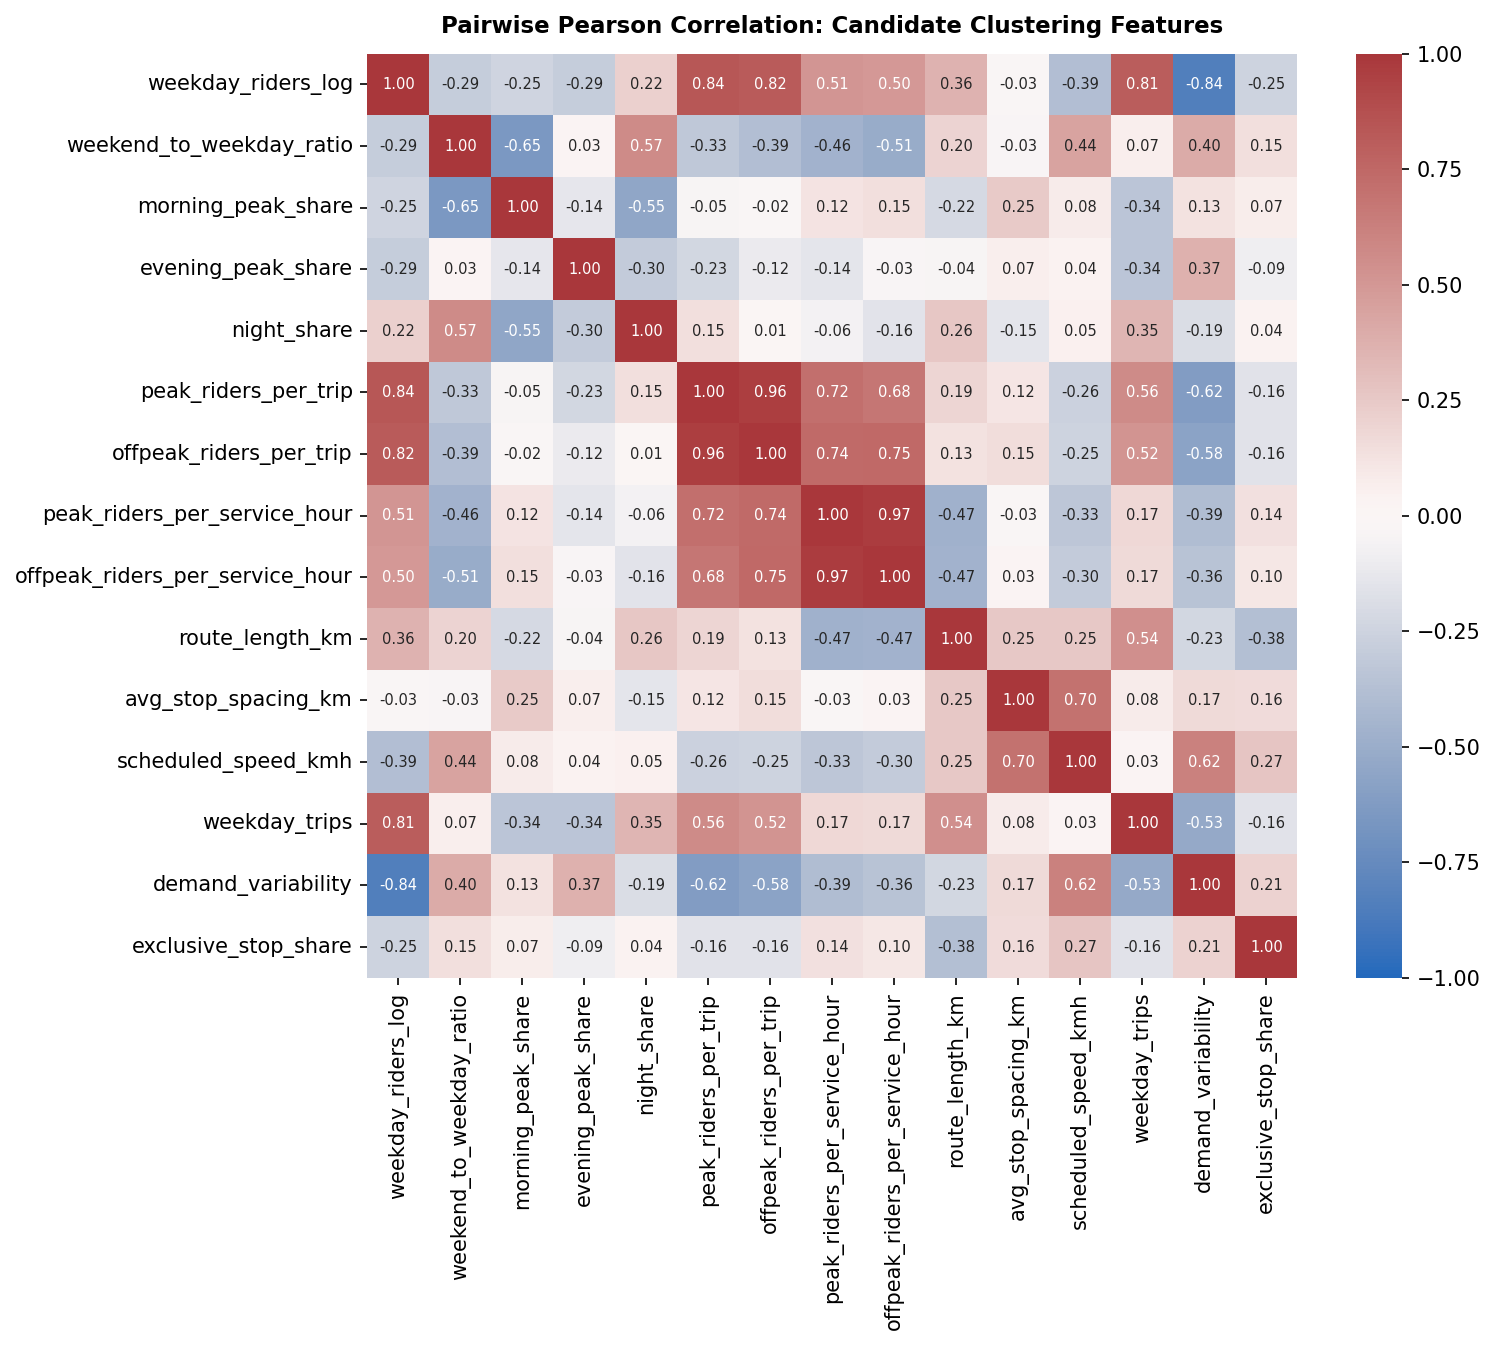

In [19]:
corr_matrix = pd.read_csv(TAB / "m2_clustering_feature_correlations.csv", index_col=0)

fig, ax = plt.subplots(figsize=(10, 8), dpi=150)
sns.heatmap(corr_matrix, cmap="vlag", vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 7}, ax=ax)
ax.set_title("Pairwise Pearson Correlation: Candidate Clustering Features", fontsize=11, fontweight="bold", pad=10)
fig.savefig(FIG / "m2_clustering_correlations.png", dpi=150, bbox_inches="tight")
plt.show()

**Finding:** Collinearity pruning ($|r| > 0.85$) removes redundant efficiency and volume pairs—most notably `peak_riders_per_trip` vs `offpeak_riders_per_trip` (**$r = 0.965$**) and `peak_riders_per_service_hour` vs `offpeak_riders_per_service_hour` (**$r = 0.971$**)—leaving **9 features** whose maximum pairwise absolute correlation is **$|r| = 0.840 < 0.85$**.

### 7.2 The 9 Chosen Route Clustering Features
The tables below display the first 15 routes of the 9 selected clustering features in standardized units (`clustering_features.parquet`) and natural unscaled units (`m2_clustering_features_unscaled.csv`).

In [20]:
cf_scaled = pd.read_parquet(DATA / "clustering_features.parquet")
cf_unscaled = pd.read_csv(TAB / "m2_clustering_features_unscaled.csv")
selected_cols = list(cf_scaled.columns)

print(f"Standardized Clustering Feature Table ({len(cf_scaled)} routes × {len(selected_cols) - 1} features, first 15 rows):")
display(cf_scaled.head(15))

print("\nUnscaled Route Clustering Features in Natural Units (first 15 rows):")
display(cf_unscaled[selected_cols].head(15))

Standardized Clustering Feature Table (41 routes × 9 features, first 15 rows):


,route,weekday_riders_log,weekend_to_weekday_ratio,morning_peak_share,night_share,peak_riders_per_service_hour,route_length_km,scheduled_speed_kmh,demand_variability,exclusive_stop_share
0,M1,0.579442,-0.093460,-0.504577,-1.302694,-0.758185,1.201827,-0.241185,-0.338681,-0.975944
1,M10,-0.431804,0.790246,-1.062098,-0.038117,-1.005210,0.050665,-0.282388,-0.009658,1.384052
2,M101,1.100410,-0.105528,-0.160278,1.067916,-0.647248,1.982972,0.418054,-0.598262,-0.967157
3,M102,0.602458,0.150240,-0.422435,0.898048,-0.464001,0.929183,-0.158780,-0.156809,-1.935684
4,M103,0.459179,0.515012,-0.899560,0.837650,-0.514753,0.989771,-0.488400,0.085411,-1.281594
5,M104,0.139964,1.798915,-1.726228,0.875398,-0.560116,0.037682,-0.570805,-0.256012,0.058679
6,M106,-1.073967,-1.338823,0.572013,-2.752239,-0.029687,-0.903587,-0.405995,2.076081,-0.613368
7,M11,0.667255,-0.017158,-0.268636,0.022281,-0.139276,0.868596,-0.282388,-0.549487,0.264992
8,M116,0.041369,-0.275651,0.433944,-0.581696,0.026455,-0.819197,-0.282388,-0.474258,-0.729132
9,M12,-1.438592,0.832290,-0.188241,0.614933,-0.260992,-0.557373,0.253244,0.490489,0.194311



Unscaled Route Clustering Features in Natural Units (first 15 rows):


,route,weekday_riders_log,weekend_to_weekday_ratio,morning_peak_share,night_share,peak_riders_per_service_hour,route_length_km,scheduled_speed_kmh,demand_variability,exclusive_stop_share
0,M1,8.9478,0.6088,0.2131,0.0853,29.94,13.68,9.8,0.1754,0.2687
1,M10,7.9724,0.8358,0.1812,0.1188,24.44,8.36,9.7,0.2152,0.8864
2,M101,9.4503,0.6057,0.2328,0.1481,32.41,17.29,11.4,0.1440,0.2710
3,M102,8.9700,0.6714,0.2178,0.1436,36.49,12.42,10.0,0.1974,0.0175
4,M103,8.8318,0.7651,0.1905,0.1420,35.36,12.70,9.2,0.2267,0.1887
5,M104,8.5239,1.0949,0.1432,0.1430,34.35,8.30,9.0,0.1854,0.5395
6,M106,7.3530,0.2889,0.2747,0.0469,46.16,3.95,9.4,0.4675,0.3636
7,M11,9.0325,0.6284,0.2266,0.1204,43.72,12.14,9.7,0.1499,0.5935
8,M116,8.4288,0.5620,0.2668,0.1044,47.41,4.34,9.7,0.1590,0.3333
9,M12,7.0013,0.8466,0.2312,0.1361,41.01,5.55,11.0,0.2757,0.5750


**Finding:** Each of the **41 routes** is represented by 9 non-collinear features spanning volume scale (`weekday_riders_log`), weekend retention (`weekend_to_weekday_ratio`), temporal concentration (`morning_peak_share`, `night_share`), service-hour load (`peak_riders_per_service_hour`), corridor geometry (`route_length_km`, `scheduled_speed_kmh`), day-to-day predictability (`demand_variability`), and network role (`exclusive_stop_share`).

## 8. Baselines

The tables and chart below compare the two validation baseline forecasts—**Same Hour Last Week (`lag_7d`)** and **4-Week Average (`lag_mean_available`)**—scored on the validation split (1 June to 31 July 2026) from `m2_baseline_forecast_overall.csv` and `m2_baseline_forecast_per_route.csv`.

Overall Validation Baseline Performance (Scored on Identical 53,585 Rows):


,model_name,evaluated_rows,coverage_pct,mae,rmse,wape_pct
0,Same hour last week (lag_7d),53585,99.15,44.27,81.45,17.48
1,4-week average (lag_mean_available),53585,99.15,35.66,63.24,14.08



Top 15 Routes by Validation Volume — Baseline Errors:


,route,total_riders,lag7_mae,lag7_rmse,lag7_wape_pct,avg4wk_mae,avg4wk_rmse,avg4wk_wape_pct,best_baseline
14,M15+,1263854,149.09,267.49,14.60,121.77,198.37,11.93,4-week average
13,M15,754794,81.47,117.91,15.80,67.29,97.54,13.05,4-week average
37,M86+,699355,62.35,114.15,13.05,54.32,91.87,11.37,4-week average
2,M101,643638,73.76,109.91,16.78,59.16,88.83,13.46,4-week average
12,M14D+,618398,53.99,92.77,12.78,46.61,75.08,11.03,4-week average
25,M4,581425,66.42,104.69,14.16,53.63,81.04,11.44,4-week average
39,M96,477198,50.92,90.78,15.62,41.39,70.82,12.70,4-week average
20,M3,469067,53.05,80.69,14.56,43.33,63.96,11.89,4-week average
31,M60+,460171,42.16,60.71,13.41,32.82,46.55,10.44,4-week average
7,M11,443690,47.42,73.77,14.05,39.26,58.08,11.64,4-week average


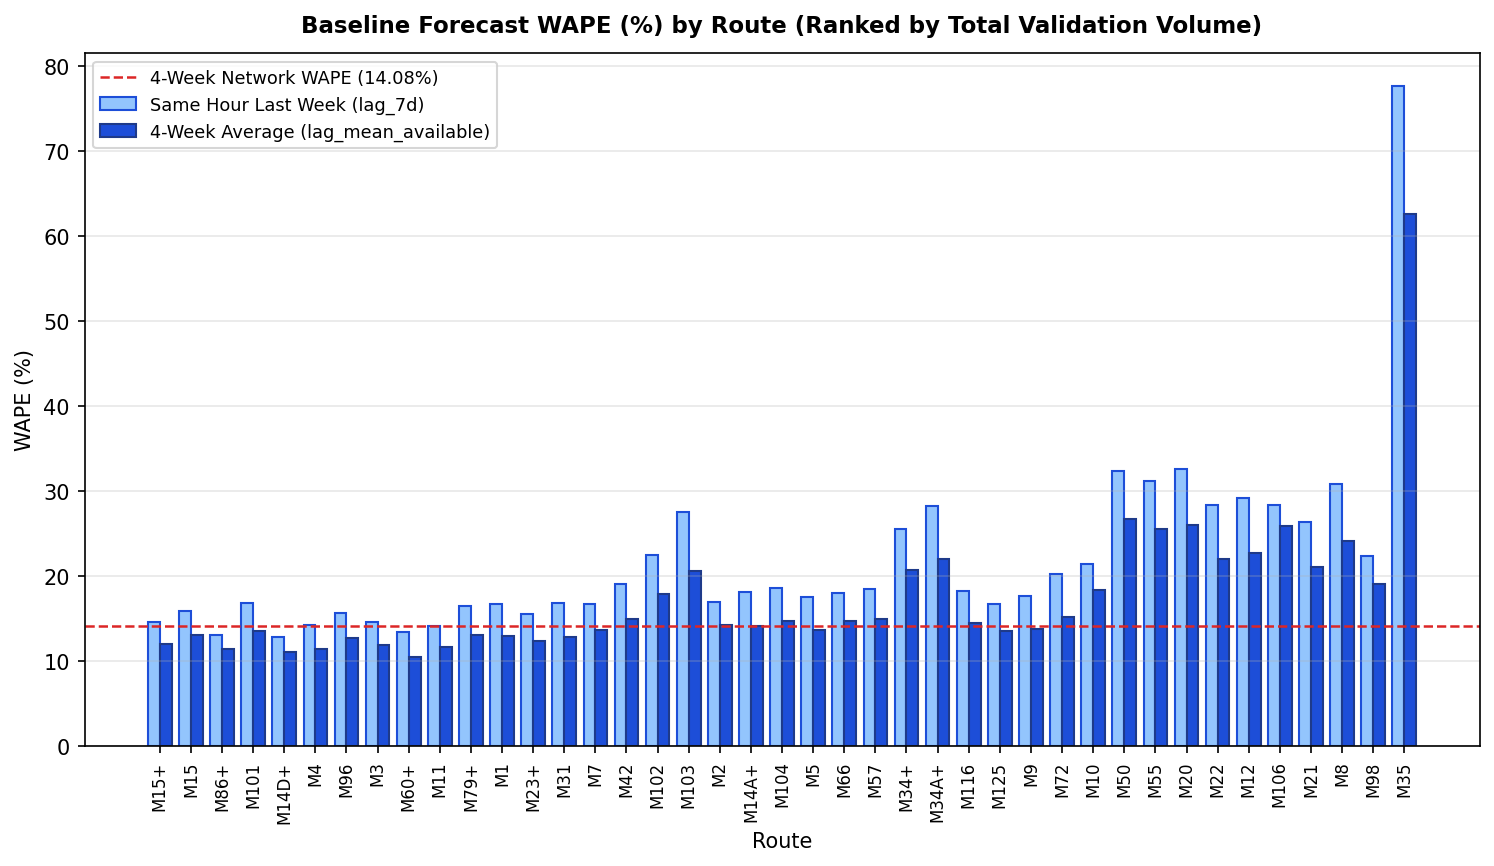

In [21]:
overall_base = pd.read_csv(TAB / "m2_baseline_forecast_overall.csv")
per_route_base = pd.read_csv(TAB / "m2_baseline_forecast_per_route.csv")

print("Overall Validation Baseline Performance (Scored on Identical 53,585 Rows):")
display(overall_base)

print("\nTop 15 Routes by Validation Volume — Baseline Errors:")
display(per_route_base.sort_values("total_riders", ascending=False).head(15))

fig, ax = plt.subplots(figsize=(12, 6), dpi=150)
sorted_r = per_route_base.sort_values("total_riders", ascending=False)
x = np.arange(len(sorted_r))
width = 0.38

ax.bar(x - width / 2, sorted_r["lag7_wape_pct"], width, label="Same Hour Last Week (lag_7d)", color="#93c5fd", edgecolor="#1d4ed8")
ax.bar(x + width / 2, sorted_r["avg4wk_wape_pct"], width, label="4-Week Average (lag_mean_available)", color="#1d4ed8", edgecolor="#1e3a8a")

ax.set_title("Baseline Forecast WAPE (%) by Route (Ranked by Total Validation Volume)", fontsize=11, fontweight="bold", pad=10)
ax.set_ylabel("WAPE (%)", fontsize=10)
ax.set_xlabel("Route", fontsize=10)
ax.set_xticks(x)
ax.set_xticklabels(sorted_r["route"], rotation=90, fontsize=8)
ax.axhline(overall_base.loc[1, "wape_pct"], color="#dc2626", linestyle="--", linewidth=1.2, label=f"4-Week Network WAPE ({overall_base.loc[1, 'wape_pct']}%)")
ax.grid(axis="y", alpha=0.3)
ax.legend(fontsize=8.5)
fig.savefig(FIG / "m2_baseline_wape_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

**Finding:** When scored on the exact same **53,585 validation rows** where both lags are present (99.15% of the 54,046 validation rows), the **4-week average (`lag_mean_available`) outperforms `lag_7d` on every single route**, reducing overall network **WAPE from 17.48% to 14.08%**, **MAE from 44.27 to 35.66 riders**, and **RMSE from 81.45 to 63.24 riders**. High-volume trunk routes achieve the lowest relative errors (`M15+` **11.45% WAPE**, `M11` **11.64%**, `M86+` **12.18%**), while low-volume routes show higher percentage errors despite small absolute errors (`M35` **36.42% WAPE** at **5.9 MAE**). All Milestone 3 forecasting models must beat the **14.08% WAPE** validation hurdle.

## 9. Models (Milestone 3)

### 9.1 Step 1: Shared Evaluation Framework & Baseline Breakdowns (`src/evaluate.py`)
The tables below load the unified Milestone 3 baseline evaluation breakdowns generated by `src/evaluate.py` on the validation period: forecasting error and bias (`pred - actual`) by day type and canonical Milestone 1 time band, alongside the heuristic classification baselines (**Rule A: `lag_7d / trips_running > threshold_p75`** vs **Rule B: `lag_mean_available / trips_running > threshold_p75`**).

In [22]:
m3_4wk_day = pd.read_csv(TAB / "m3_eval_baseline_4wk_by_day_type.csv")
m3_4wk_band = pd.read_csv(TAB / "m3_eval_baseline_4wk_by_time_band.csv")
m3_clf_7d = pd.read_csv(TAB / "m3_eval_baseline_class_7d_overall.csv")
m3_clf_4wk = pd.read_csv(TAB / "m3_eval_baseline_class_4wk_overall.csv")
m3_clf_cm = pd.read_csv(TAB / "m3_eval_baseline_class_4wk_confusion_matrix.csv")

print("4-Week Average Forecasting Baseline — Breakdown by Day Type (53,585 rows):")
display(m3_4wk_day[["model_name", "day_type", "n_eval", "mae", "rmse", "wape_pct", "bias_pred_minus_actual"]])

print("\n4-Week Average Forecasting Baseline — Breakdown by Canonical Time Band:")
display(m3_4wk_band[["time_band", "time_band_label", "n_eval", "mae", "rmse", "wape_pct", "bias_pred_minus_actual"]])

print("\nClassification Heuristic Baselines on Active-Service Validation Hours (53,406 rows):")
display(pd.concat([m3_clf_7d, m3_clf_4wk], ignore_index=True)[
    ["model_name", "n_eval", "actual_pos", "pred_pos", "precision", "recall", "f1", "pr_auc", "roc_auc"]
])

print("\nRule B (4-Week Average Heuristic) Validation Confusion Matrix:")
display(m3_clf_cm)

4-Week Average Forecasting Baseline — Breakdown by Day Type (53,585 rows):


,model_name,day_type,n_eval,mae,rmse,wape_pct,bias_pred_minus_actual
0,4-Week Average Baseline,Typical Weekday,38200,33.68,57.47,12.00,0.56
1,4-Week Average Baseline,Typical Saturday,5988,35.83,59.45,18.18,-0.45
2,4-Week Average Baseline,Typical Sunday,6801,32.94,55.97,19.51,-0.99
3,4-Week Average Baseline,Special/Excluded,2596,71.45,132.62,36.00,59.50



4-Week Average Forecasting Baseline — Breakdown by Canonical Time Band:


,time_band,time_band_label,n_eval,mae,rmse,wape_pct,bias_pred_minus_actual
0,early_morning,Early Morning (04:00–06:59),5811,12.83,28.36,14.71,0.82
1,morning_peak,Morning Peak (07:00–09:59),7417,49.19,88.18,13.35,3.86
2,midday,Midday (10:00–15:59),14727,45.75,68.90,12.90,5.60
3,evening_peak,Evening Peak (16:00–18:59),7446,59.43,89.91,13.94,5.45
4,night,Night (19:00–03:59),18184,19.52,34.66,18.40,0.56



Classification Heuristic Baselines on Active-Service Validation Hours (53,406 rows):


,model_name,n_eval,actual_pos,pred_pos,precision,recall,f1,pr_auc,roc_auc
0,Rule A: Prior-Week Heuristic (lag_7d / trips),53406,12987,13263,0.6211,0.6342,0.6276,0.6295,0.8557
1,Rule B: 4-Week Average Heuristic (lag_mean / t...,53406,12987,13081,0.6641,0.6689,0.6665,0.6904,0.8955



Rule B (4-Week Average Heuristic) Validation Confusion Matrix:


,Actual Class,Pred Normal (0),Pred High (1),Total Actual,Model
0,Actual Normal Demand (0),36025,4394,40419,Rule B: 4-Week Average Heuristic (lag_mean / t...
1,Actual High Demand (1),4300,8687,12987,Rule B: 4-Week Average Heuristic (lag_mean / t...
2,Total Predicted,40325,13081,53406,Rule B: 4-Week Average Heuristic (lag_mean / t...


**Finding:** Breaking down the **14.08% WAPE** (bias **+3.11 riders**) 4-week average baseline reveals strong accuracy on **Typical Weekdays (12.00% WAPE, +0.56 bias)** and during **Midday (12.90% WAPE)** and **Morning/Evening Peaks (13.35% / 13.94% WAPE)**, whereas **Special/Excluded holiday dates** suffer **36.00% WAPE and +59.50 riders over-prediction bias** because regular prior-week lags do not anticipate holiday schedule reductions. For `high_demand_per_trip` classification across the **53,406 active-service validation hours** (`trips_running > 0`), **Rule B (4-week heuristic)** beats **Rule A (7-day heuristic)** across every metric, raising **F1 from 0.6276 to 0.6665**, **Precision from 0.6211 to 0.6641**, **Recall from 0.6342 to 0.6689**, and **PR-AUC from 0.6295 to 0.6904**—setting the classification hurdle for Milestone 3.

*(Upcoming Milestone 3 sections — Forecasting Models, Classification Models, Route Clustering, and Operational Suggestions — will be appended here as each step is completed.)*